
# Pemodelan Non-Linear Berbasis Tanimoto Kernel untuk Prediksi Afinitas Inhibitor USP5

### Eksplorasi Machine Learning pada Dataset 80 Senyawa Inhibitor USP5

**Metode:** Tanimoto-Kernel Non-Linear Blend

**Dataset:** USP5_pKd_80.csv

**Target prediksi:** pKd = 9 − log10(Kd [nM])

---

## 1. Persiapan Environment dan Library

### 1.1 Latar Belakang

Penelitian ini melanjutkan pengembangan model prediksi afinitas inhibitor USP5 menggunakan dataset 80 senyawa hasil kurasi KNIME.

Pendekatan sebelumnya meliputi GraphConvModel (GNN) dan ML Descriptor Ensemble.

Pada eksperimen ini digunakan pendekatan non-linear berbasis Tanimoto Kernel untuk mengevaluasi hubungan kemiripan struktur molekul dengan afinitas penghambatan USP5.

### 1.2 Tujuan

1. Mengembangkan model non-linear untuk memprediksi nilai pKd inhibitor USP5.
2. Mengevaluasi algoritma berbasis Tanimoto Kernel dan model non-linear lainnya.
3. Membandingkan performa menggunakan Random dan Scaffold Cross-Validation.
4. Mengevaluasi kestabilan model, residual, dan applicability domain.
5. Membandingkan hasil dengan model GNN dan ML Ensemble sebelumnya.

### 1.3 Persiapan

Tahap pertama bertujuan memastikan seluruh library tersedia dan environment Python sesuai untuk menjalankan eksperimen.

Seluruh hasil Tanimoto disimpan pada direktori terpisah agar tidak mengubah hasil penelitian ML Ensemble sebelumnya.


In [5]:

import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import (
    Descriptors,
    rdFingerprintGenerator,
    MACCSkeys
)
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from scipy.stats import pearsonr, spearmanr
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import joblib
import sklearn
import rdkit
import xgboost
import lightgbm

RDLogger.DisableLog("rdApp.*")

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

# Folder output khusus Tanimoto
OUT = Path("/data/Aliya/model/Hasil_Tanimoto_USP5_80")
OUT.mkdir(parents=True, exist_ok=True)

# Pengaturan grafik berwarna
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25
})

print("=== VERIFIKASI ENVIRONMENT TANIMOTO USP5 ===")
print("Python:", sys.version.split()[0])
print("RDKit:", rdkit.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)
print("Random State:", RANDOM_STATE)
print("Folder output:", OUT)
print("\n=== PERSIAPAN BERHASIL ===")


=== VERIFIKASI ENVIRONMENT TANIMOTO USP5 ===
Python: 3.10.12
RDKit: 2026.09.1
Scikit-learn: 1.7.2
XGBoost: 3.2.0
LightGBM: 4.7.0
Random State: 0
Folder output: /data/Aliya/model/Hasil_Tanimoto_USP5_80

=== PERSIAPAN BERHASIL ===



## 2. Pemuatan Dataset dan Eksplorasi Awal

### 2.1 Tujuan

Tahap ini bertujuan memuat dan memeriksa dataset 80 senyawa inhibitor USP5 sebelum dilakukan pemodelan non-linear berbasis Tanimoto Kernel.

### Mengapa tahap ini diperlukan?

Kualitas dataset memengaruhi kemampuan model dalam mempelajari hubungan struktur molekul dan aktivitas inhibitor USP5.

Pemeriksaan meliputi:

1. Jumlah senyawa dan kelengkapan data.
2. Validitas struktur SMILES.
3. Distribusi nilai pKd.
4. Jumlah scaffold Bemis–Murcko.
5. Jumlah senyawa dengan pKd tinggi (> 5).

### Mengapa scaffold diperiksa?

Scaffold merupakan kerangka dasar struktur molekul. Identifikasi scaffold diperlukan untuk melakukan Scaffold Cross-Validation, sehingga model dapat dievaluasi pada kerangka molekul yang tidak ditemukan dalam data training.

Dataset yang digunakan sama dengan penelitian ML Ensemble sebelumnya, yaitu `USP5_pKd_80.csv`.


In [6]:

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

CSV_URL = (
    "https://raw.githubusercontent.com/"
    "aliyarahmaazizah/USP5/main/USP5_pKd_80.csv"
)

CSV_LOCAL = OUT / "USP5_pKd_80.csv"

# Membaca dataset
if CSV_LOCAL.exists():
    df = pd.read_csv(CSV_LOCAL)
    print("Dataset dibaca dari file lokal")
else:
    df = pd.read_csv(CSV_URL)
    df.to_csv(CSV_LOCAL, index=False)
    print("Dataset diunduh dari GitHub")

# Memastikan nama kolom sesuai
df.columns = df.columns.str.strip()

required = {"Molecule ChEMBL ID", "Smiles", "pKd"}
assert required.issubset(df.columns), (
    f"Kolom tidak sesuai: {df.columns.tolist()}"
)

# Memeriksa dataset
assert len(df) == 80, "Jumlah senyawa bukan 80"

df["pKd"] = pd.to_numeric(df["pKd"], errors="raise")
assert df["pKd"].notna().all()

# SMILES menjadi objek molekul
df["mol"] = df["Smiles"].apply(Chem.MolFromSmiles)

assert df["mol"].notna().all(), (
    "Terdapat struktur SMILES tidak valid"
)

# Identifikasi scaffold
df["scaffold"] = df["mol"].apply(
    lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m)
)

# Variabel untuk pemodelan
mols = df["mol"].tolist()
y = df["pKd"].to_numpy(dtype=float)
groups = df["scaffold"].to_numpy()

print("\n=== EKSPLORASI DATASET USP5 ===")
print("Jumlah senyawa:", len(df))
print("SMILES unik:", df["Smiles"].nunique())
print("Scaffold unik:", df["scaffold"].nunique())
print("pKd minimum:", round(y.min(), 4))
print("pKd median:", round(np.median(y), 4))
print("pKd maksimum:", round(y.max(), 4))
print("pKd mean:", round(y.mean(), 4))
print("pKd SD:", round(y.std(ddof=1), 4))
print("Jumlah pKd > 5:", int((y > 5).sum()))

display(
    df[[
        "Molecule ChEMBL ID",
        "Smiles",
        "pKd",
        "scaffold"
    ]].head()
)


Dataset dibaca dari file lokal

=== EKSPLORASI DATASET USP5 ===
Jumlah senyawa: 80
SMILES unik: 80
Scaffold unik: 38
pKd minimum: 3.0315
pKd median: 4.0996
pKd maksimum: 5.5528
pKd mean: 4.1219
pKd SD: 0.6373
Jumlah pKd > 5: 9


,Molecule ChEMBL ID,Smiles,pKd,scaffold
0,CHEMBL4573416,O=C(O)Cn1cc2ccccc2n1,3.031517,c1ccc2n[nH]cc2c1
1,CHEMBL4576514,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.036212,c1ccc(-c2nnco2)cc1
2,CHEMBL4563831,O=C(O)CCc1ncc(-c2ccccc2)o1,3.040959,c1ccc(-c2cnco2)cc1
3,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.075721,c1ccsc1
4,CHEMBL4532335,O=C(O)Cc1nc2ccccc2o1,3.113509,c1ccc2ocnc2c1



### 2.2 Visualisasi Distribusi Dataset

Visualisasi eksploratif dilakukan untuk memahami distribusi nilai pKd serta keragaman scaffold molekul sebelum proses featurization dan pemodelan non-linear.

Analisis meliputi:

1. Distribusi nilai pKd inhibitor USP5.
2. Distribusi kumulatif nilai pKd.
3. Jumlah senyawa berdasarkan scaffold Bemis–Murcko.
4. Proporsi senyawa berdasarkan kelompok pKd.

Distribusi pKd diperlukan untuk mengidentifikasi ketidakseimbangan rentang aktivitas, sedangkan distribusi scaffold digunakan untuk memahami keragaman struktur kimia dalam dataset.

Hasil eksplorasi menjadi dasar interpretasi performa Random dan Scaffold Cross-Validation pada tahap berikutnya.


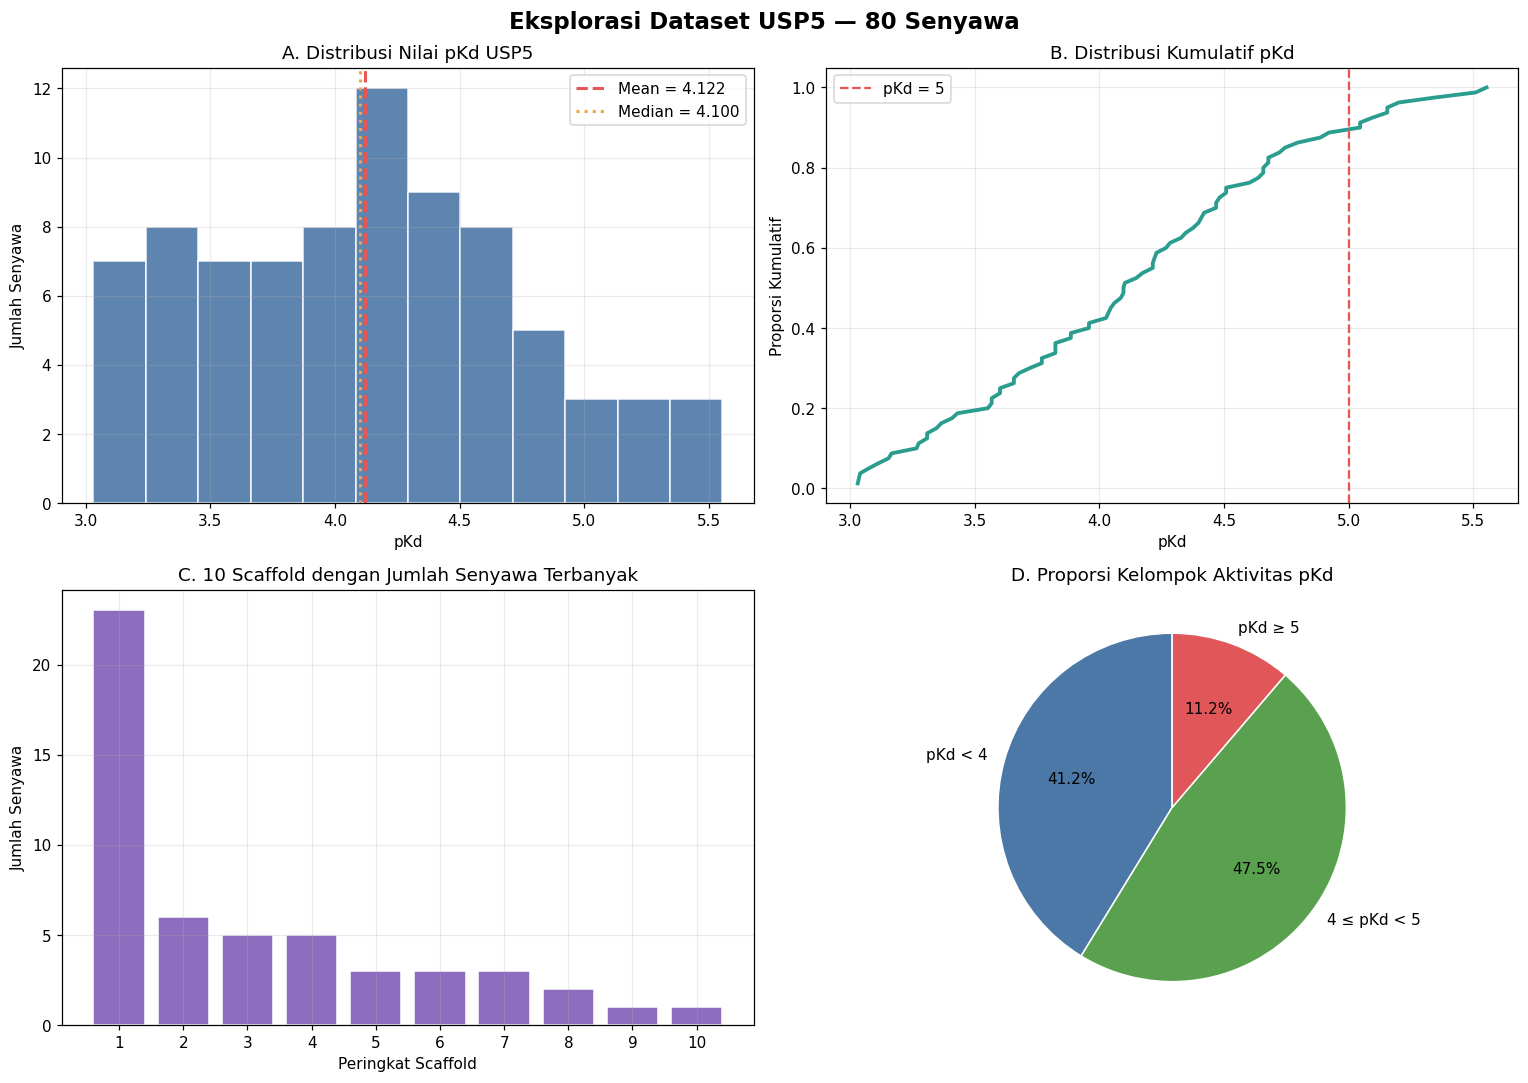

=== RINGKASAN DISTRIBUSI ===
Jumlah kelompok pKd: {'pKd < 4': 33, '4 ≤ pKd < 5': 38, 'pKd ≥ 5': 9}
Jumlah scaffold unik: 38
Jumlah scaffold singleton: 30
Scaffold terbesar: 23 senyawa
Gambar berhasil disimpan.


In [7]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.patches import Patch

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# A. Histogram pKd
axes[0, 0].hist(
    y,
    bins=12,
    color="#4C78A8",
    edgecolor="white",
    alpha=0.9
)

axes[0, 0].axvline(
    np.mean(y),
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {np.mean(y):.3f}"
)

axes[0, 0].axvline(
    np.median(y),
    color="#F2A541",
    linestyle=":",
    linewidth=2,
    label=f"Median = {np.median(y):.3f}"
)

axes[0, 0].set_title("A. Distribusi Nilai pKd USP5")
axes[0, 0].set_xlabel("pKd")
axes[0, 0].set_ylabel("Jumlah Senyawa")
axes[0, 0].legend()

# B. Distribusi kumulatif
y_sorted = np.sort(y)
cdf = np.arange(1, len(y_sorted) + 1) / len(y_sorted)

axes[0, 1].plot(
    y_sorted,
    cdf,
    color="#2A9D8F",
    linewidth=2.5
)

axes[0, 1].axvline(
    5,
    color="#E45756",
    linestyle="--",
    label="pKd = 5"
)

axes[0, 1].set_title("B. Distribusi Kumulatif pKd")
axes[0, 1].set_xlabel("pKd")
axes[0, 1].set_ylabel("Proporsi Kumulatif")
axes[0, 1].legend()

# C. Ukuran scaffold terbanyak
scaffold_counts = df["scaffold"].value_counts()
top10_scaffold = scaffold_counts.head(10)

axes[1, 0].bar(
    range(1, len(top10_scaffold) + 1),
    top10_scaffold.values,
    color="#8E6CBE",
    edgecolor="white"
)

axes[1, 0].set_title("C. 10 Scaffold dengan Jumlah Senyawa Terbanyak")
axes[1, 0].set_xlabel("Peringkat Scaffold")
axes[1, 0].set_ylabel("Jumlah Senyawa")
axes[1, 0].set_xticks(range(1, len(top10_scaffold) + 1))

# D. Komposisi kelompok pKd
label_kelompok = [
    "pKd < 4",
    "4 ≤ pKd < 5",
    "pKd ≥ 5"
]

jumlah_kelompok = [
    np.sum(y < 4),
    np.sum((y >= 4) & (y < 5)),
    np.sum(y >= 5)
]

warna_kelompok = ["#4C78A8", "#59A14F", "#E15759"]

axes[1, 1].pie(
    jumlah_kelompok,
    labels=label_kelompok,
    autopct="%1.1f%%",
    startangle=90,
    colors=warna_kelompok,
    wedgeprops={"edgecolor": "white"}
)

axes[1, 1].set_title("D. Proporsi Kelompok Aktivitas pKd")

plt.suptitle(
    "Eksplorasi Dataset USP5 — 80 Senyawa",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_EDA_80.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=== RINGKASAN DISTRIBUSI ===")
print("Jumlah kelompok pKd:", dict(zip(label_kelompok, jumlah_kelompok)))
print("Jumlah scaffold unik:", len(scaffold_counts))
print("Jumlah scaffold singleton:", int((scaffold_counts == 1).sum()))
print("Scaffold terbesar:", int(scaffold_counts.iloc[0]), "senyawa")
print("Gambar berhasil disimpan.")



### 2.3 Interpretasi Hasil Eksplorasi Dataset

Hasil eksplorasi menunjukkan bahwa dataset USP5 terdiri atas 80 senyawa dengan 80 SMILES unik dan 38 scaffold Bemis–Murcko.

Nilai pKd berkisar antara 3,0315–5,5528, dengan rata-rata 4,1219 dan median 4,0996.

Distribusi aktivitas menunjukkan bahwa 33 senyawa (41,25%) memiliki pKd < 4, sebanyak 38 senyawa (47,50%) berada pada rentang 4 ≤ pKd < 5, dan hanya 9 senyawa (11,25%) memiliki pKd ≥ 5.

Analisis scaffold menunjukkan adanya ketidakseimbangan representasi struktur. Scaffold terbesar mencakup 23 senyawa, sedangkan 30 dari 38 scaffold hanya memiliki satu senyawa.

Kondisi tersebut dapat memengaruhi kemampuan model mempelajari hubungan struktur–aktivitas dan memprediksi senyawa dengan scaffold yang belum ditemukan selama pelatihan.

Oleh karena itu, penelitian menggunakan Random Cross-Validation dan Scaffold Cross-Validation untuk membandingkan performa interpolasi pada data acak dengan generalisasi terhadap scaffold yang berbeda.



## 3. Featurization Molekul

### 3.1 Tujuan

Tahap featurization mengubah struktur molekul dalam format SMILES menjadi representasi numerik yang dapat digunakan oleh algoritma machine learning non-linear.

Pendekatan yang digunakan mengikuti notebook referensi Pak Ridwan dengan tiga kelompok fitur:

1. **RDKit Descriptors (DESC):** merepresentasikan sifat fisikokimia molekul, seperti berat molekul, lipofilisitas, polaritas, dan sifat topologi.
2. **Morgan Fingerprint (FP):** merepresentasikan keberadaan lingkungan atom dan sub-struktur molekul menggunakan fingerprint biner radius 2.
3. **MACCS Keys (MACCS):** merepresentasikan pola struktur kimia melalui kunci sub-struktur yang telah didefinisikan.

### 3.2 Seleksi Fitur

Deskriptor RDKit dibersihkan dengan menghilangkan:

- Deskriptor yang mengandung nilai NaN atau tak hingga.
- Deskriptor dengan varians nol.
- Deskriptor yang memiliki korelasi absolut lebih dari 0,95 dengan deskriptor lain.

Morgan Fingerprint menggunakan 1.024 bit dan mempertahankan bit yang aktif pada minimal empat senyawa.

MACCS Keys mempertahankan fitur yang memiliki variasi antar-senyawa.

### 3.3 Matriks Fitur

Representasi molekul disusun sebagai:

- DESC: deskriptor fisikokimia.
- FP: Morgan binary fingerprint terpilih.
- MACCS: MACCS keys terpilih.
- FPM: gabungan Morgan dan MACCS.
- ALL: gabungan deskriptor, Morgan, dan MACCS.

Kombinasi FPM digunakan sebagai input utama perhitungan Tanimoto Kernel.

Penyaringan fitur pada tahap eksplorasi ini mengikuti referensi asli. Untuk estimasi performa generalisasi yang sepenuhnya bebas kebocoran informasi, seleksi fitur berbasis keseluruhan dataset sebaiknya diuji ulang dengan prosedur seleksi yang dilakukan di dalam setiap fold training.


In [8]:

from rdkit.Chem import Descriptors, rdFingerprintGenerator, MACCSkeys
import numpy as np
import pandas as pd

# 1. RDKit descriptors
def build_descriptors(mols, corr_cut=0.95, verbose=True):
    names = [n for n, _ in Descriptors._descList]

    rows = []
    for m in mols:
        vals = []
        for _, fn in Descriptors._descList:
            try:
                v = fn(m)
            except Exception:
                v = np.nan
            vals.append(v)
        rows.append(vals)

    Xd = pd.DataFrame(rows, columns=names)
    Xd = Xd.replace([np.inf, -np.inf], np.nan)

    n0 = Xd.shape[1]

    Xd = Xd.loc[:, Xd.isna().sum() == 0]
    n1 = Xd.shape[1]

    Xd = Xd.loc[:, Xd.std() > 0]
    n2 = Xd.shape[1]

    cm = Xd.corr().abs()
    upper = np.triu(np.ones(cm.shape), 1).astype(bool)

    drop = [
        c for i, c in enumerate(cm.columns)
        if (cm.values[:, i][upper[:, i]] > corr_cut).any()
    ]

    Xd = Xd.drop(columns=drop)

    if verbose:
        print(
            f"Deskriptor: {n0} mentah -> "
            f"{n1} tanpa NaN -> "
            f"{n2} varians > 0 -> "
            f"{Xd.shape[1]} setelah korelasi"
        )

    return Xd


# 2. Morgan binary fingerprint
def build_morgan(
    mols,
    radius=2,
    nbits=1024,
    min_count=4,
    counts=False
):
    gen = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=nbits
    )

    if counts:
        f = lambda m: gen.GetCountFingerprintAsNumPy(m)
    else:
        f = lambda m: gen.GetFingerprintAsNumPy(m)

    F = np.array([f(m) for m in mols], dtype=float)

    mask = (F > 0).sum(0) >= min_count

    print(
        f"Morgan r={radius}: {nbits} bit -> "
        f"{int(mask.sum())} bit aktif pada >= {min_count} molekul"
    )

    return F[:, mask], mask


# 3. MACCS keys
def build_maccs(mols):
    K = np.array(
        [
            np.array(MACCSkeys.GenMACCSKeys(m))
            for m in mols
        ],
        dtype=float
    )

    mask = K.std(0) > 0

    print(
        f"MACCS: 167 key -> "
        f"{int(mask.sum())} key informatif"
    )

    return K[:, mask], mask


# 4. Bangun ketiga kelompok fitur
DESC_df = build_descriptors(df["mol"])

FP, FP_MASK = build_morgan(df["mol"])

MACCS, MACCS_MASK = build_maccs(df["mol"])


# 5. Susun matriks fitur
X_DESC = DESC_df.to_numpy()

X_FPM = np.hstack([FP, MACCS])

X_ALL = np.hstack([X_DESC, FP, MACCS])


# 6. Simpan daftar matriks
BLOCKS = {
    "DESC": X_DESC,
    "FP": FP,
    "MACCS": MACCS,
    "FPM": X_FPM,
    "ALL": X_ALL
}

print("\n=== HASIL FEATURIZATION USP5 ===")

for nama, matriks in BLOCKS.items():
    print(
        f"Blok {nama:6s} -> {matriks.shape}"
    )

# Pemeriksaan akhir
assert all(v.shape[0] == 80 for v in BLOCKS.values())
assert np.isfinite(X_ALL).all()

print("\n=== FEATURIZATION BERHASIL ===")


Deskriptor: 217 mentah -> 209 tanpa NaN -> 150 varians > 0 -> 108 setelah korelasi
Morgan r=2: 1024 bit -> 137 bit aktif pada >= 4 molekul
MACCS: 167 key -> 121 key informatif

=== HASIL FEATURIZATION USP5 ===
Blok DESC   -> (80, 108)
Blok FP     -> (80, 137)
Blok MACCS  -> (80, 121)
Blok FPM    -> (80, 258)
Blok ALL    -> (80, 366)

=== FEATURIZATION BERHASIL ===



### 3.4 Hasil dan Interpretasi Featurization

Proses featurization berhasil menghasilkan tiga representasi molekul dari 80 senyawa inhibitor USP5.

RDKit Descriptors menghasilkan 217 deskriptor awal, kemudian berkurang menjadi 108 deskriptor setelah penghapusan nilai tidak valid, fitur konstan, dan fitur berkorelasi tinggi.

Morgan Binary Fingerprint radius 2 dengan ukuran awal 1.024 bit menghasilkan 137 fitur setelah seleksi berdasarkan frekuensi kemunculan minimal empat molekul.

MACCS Keys menghasilkan 121 fitur dengan variasi antar-senyawa dari 167 posisi awal.

Penggabungan Morgan Fingerprint dan MACCS Keys menghasilkan matriks FPM berukuran 80 × 258, sedangkan gabungan seluruh representasi menghasilkan matriks ALL berukuran 80 × 366.

Hasil ini menunjukkan bahwa seluruh 80 senyawa berhasil direpresentasikan secara numerik dan siap digunakan dalam analisis kemiripan molekul berbasis Tanimoto Kernel.

Seleksi fitur dilakukan sebagai bagian dari eksplorasi awal. Pada evaluasi prediktif, penggunaan informasi dari keseluruhan dataset dalam seleksi fitur perlu diperhatikan untuk mencegah potensi kebocoran data.



## 4. Perhitungan Tanimoto Kernel

### 4.1 Tujuan

Tahap ini bertujuan membangun matriks kemiripan molekul menggunakan Tanimoto Kernel berdasarkan gabungan Morgan Binary Fingerprint dan MACCS Keys.

Tanimoto Kernel menghitung kemiripan pasangan molekul berdasarkan jumlah fitur fingerprint yang sama dibandingkan dengan keseluruhan fitur aktif pada kedua molekul.

Nilai Tanimoto berada pada rentang 0–1:

- Nilai 0: tidak memiliki fitur fingerprint aktif yang sama.
- Nilai 1: kedua representasi fingerprint identik.
- Nilai antara 0 dan 1: menunjukkan tingkat kemiripan struktur berdasarkan fingerprint yang digunakan.

### 4.2 Perhitungan Matriks Kernel

Matriks Tanimoto dihitung dari 80 senyawa, sehingga menghasilkan matriks berukuran 80 × 80.

Analisis meliputi:

1. Pemeriksaan bentuk dan simetri matriks.
2. Pemeriksaan rentang nilai kemiripan.
3. Pemeriksaan eigenvalue untuk menilai validitas kernel.
4. Visualisasi heatmap kemiripan molekul.
5. Distribusi kemiripan terhadap tetangga terdekat.

Matriks ini akan digunakan sebagai dasar model Support Vector Regression dan Kernel Ridge Regression berbasis Tanimoto Kernel.

Kemiripan antarsenyawa pada tahap ini bersifat deskriptif. Dalam cross-validation, model hanya boleh menggunakan data training untuk membangun bagian kernel yang digunakan dalam fitting.


=== VERIFIKASI TANIMOTO KERNEL ===
Ukuran matriks: (80, 80)
Tanimoto minimum: 0.1129
Tanimoto maksimum: 1.0
Matriks simetris: True
Diagonal mendekati 1: True
Eigenvalue minimum: 6.634610e-03
=== KERNEL BERHASIL DIVERIFIKASI ===


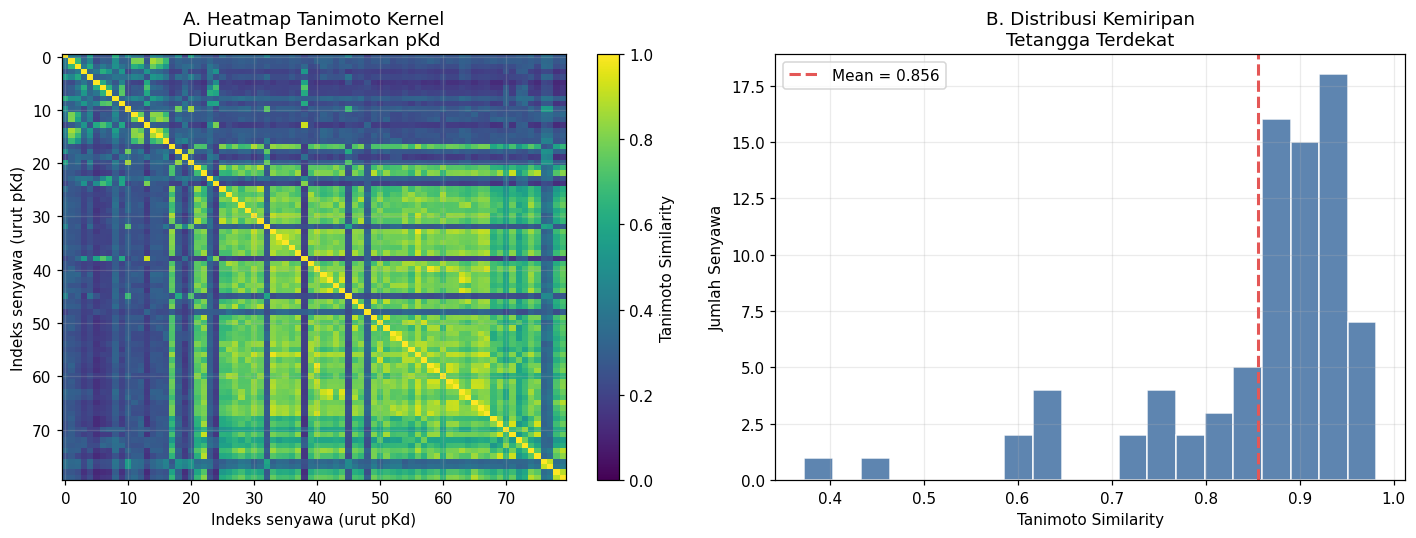


=== RINGKASAN KEMIRIPAN ===
Mean: 0.8558
Median: 0.8918
Minimum: 0.3729
Maksimum: 0.9817
Jumlah similarity < 0.5: 2


In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Fungsi kernel Tanimoto
def tanimoto_kernel(A, B):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)

    inter = A @ B.T
    a = (A * A).sum(axis=1)[:, None]
    b = (B * B).sum(axis=1)[None, :]

    return inter / (a + b - inter + 1e-12)


# Matriks kemiripan 80 × 80
K = tanimoto_kernel(X_FPM, X_FPM)

# Verifikasi
eig = np.linalg.eigvalsh(K)

print("=== VERIFIKASI TANIMOTO KERNEL ===")
print("Ukuran matriks:", K.shape)
print("Tanimoto minimum:", round(K.min(), 4))
print("Tanimoto maksimum:", round(K.max(), 4))
print("Matriks simetris:", np.allclose(K, K.T))
print("Diagonal mendekati 1:", np.allclose(np.diag(K), 1))
print("Eigenvalue minimum:", f"{eig.min():.6e}")

assert K.shape == (80, 80)
assert np.allclose(K, K.T)
assert np.allclose(np.diag(K), 1)
assert eig.min() >= -1e-8

print("=== KERNEL BERHASIL DIVERIFIKASI ===")

# Kemiripan dengan tetangga terdekat selain diri sendiri
Koff = K.copy()
np.fill_diagonal(Koff, 0)

nn_sim = Koff.max(axis=1)

# Urutkan molekul berdasarkan pKd
order = np.argsort(y)
K_sorted = K[np.ix_(order, order)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# A. Heatmap
im = axes[0].imshow(
    K_sorted,
    cmap="viridis",
    vmin=0,
    vmax=1,
    aspect="auto"
)

axes[0].set_title(
    "A. Heatmap Tanimoto Kernel\nDiurutkan Berdasarkan pKd"
)
axes[0].set_xlabel("Indeks senyawa (urut pKd)")
axes[0].set_ylabel("Indeks senyawa (urut pKd)")

fig.colorbar(
    im,
    ax=axes[0],
    label="Tanimoto Similarity"
)

# B. Distribusi tetangga terdekat
axes[1].hist(
    nn_sim,
    bins=20,
    color="#4C78A8",
    edgecolor="white",
    alpha=0.9
)

axes[1].axvline(
    nn_sim.mean(),
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {nn_sim.mean():.3f}"
)

axes[1].set_title(
    "B. Distribusi Kemiripan\nTetangga Terdekat"
)
axes[1].set_xlabel("Tanimoto Similarity")
axes[1].set_ylabel("Jumlah Senyawa")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_Kernel_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n=== RINGKASAN KEMIRIPAN ===")
print("Mean:", round(nn_sim.mean(), 4))
print("Median:", round(np.median(nn_sim), 4))
print("Minimum:", round(nn_sim.min(), 4))
print("Maksimum:", round(nn_sim.max(), 4))
print("Jumlah similarity < 0.5:", int((nn_sim < 0.5).sum()))



### 4.3 Hasil dan Interpretasi Tanimoto Kernel

Tanimoto Kernel digunakan untuk mengukur kemiripan struktur antarsenyawa berdasarkan gabungan Morgan Fingerprint dan MACCS Keys.

Perhitungan menghasilkan matriks berukuran **80 × 80**, bersifat simetris, dengan diagonal bernilai 1 dan eigenvalue minimum positif (0,00635), sehingga matriks memenuhi pemeriksaan numerik kernel.

**Hasil analisis kemiripan:**

- Rata-rata kemiripan tetangga terdekat: **0,8558**.
- Median kemiripan: **0,8918**.
- Kemiripan minimum: **0,3729**.
- Kemiripan maksimum: **0,9817**.
- Senyawa dengan kemiripan tetangga terdekat < 0,5: **2 senyawa**.

Heatmap menunjukkan adanya kelompok senyawa dengan fingerprint yang relatif mirip, sedangkan histogram memperlihatkan bahwa sebagian besar senyawa memiliki tetangga struktural dengan nilai Tanimoto tinggi.

**Interpretasi:** Dataset USP5 memiliki banyak senyawa yang saling mirip berdasarkan fingerprint molekul. Kondisi ini berpotensi membantu model berbasis Tanimoto mempelajari hubungan struktur–aktivitas, tetapi tidak menjamin kemiripan nilai pKd maupun akurasi prediksi.

Oleh karena itu, performa model tetap perlu diuji menggunakan Random Cross-Validation dan Scaffold Cross-Validation untuk menilai kemampuan prediksi terhadap senyawa yang belum digunakan dalam pelatihan.



## 5. Protokol Validasi Model

### 5.1 Tujuan

Tahap ini bertujuan menyiapkan metode validasi untuk mengevaluasi kemampuan prediksi model non-linear berbasis Tanimoto Kernel.

Dua protokol validasi digunakan:

1. **Random 5-Fold Cross-Validation:** Dataset dibagi menjadi lima fold secara acak untuk mengevaluasi kemampuan prediksi pada pembagian data acak.
2. **Scaffold 5-Fold Cross-Validation:** Senyawa dikelompokkan berdasarkan Bemis–Murcko scaffold sehingga scaffold pada data pengujian tidak muncul dalam data training.

### 5.2 Pengulangan dan Seed

Validasi dilakukan dengan lima pengulangan pada masing-masing protokol.

- Random CV untuk seleksi model: seed 100–104.
- Scaffold CV untuk seleksi model: seed 200–204.
- Random CV untuk verifikasi: seed 700–704.
- Scaffold CV untuk verifikasi: seed 800–804.

Pemisahan seed seleksi dan verifikasi digunakan untuk mengurangi ketergantungan hasil terhadap pembagian data yang digunakan saat pemilihan model.

### 5.3 Evaluasi Performa

Metrik evaluasi meliputi:

- R²: kemampuan model menjelaskan variasi pKd.
- RMSE: besarnya kesalahan prediksi dengan penalti lebih besar untuk kesalahan ekstrem.
- MAE: rata-rata kesalahan absolut prediksi.
- Korelasi Pearson dan Spearman: hubungan antara pKd eksperimen dan prediksi.

Protokol ini memungkinkan perbandingan performa model pada pembagian acak dan pada senyawa dengan scaffold yang belum ditemukan selama training.

Hasil tetap merupakan evaluasi internal karena seluruh eksperimen menggunakan dataset 80 senyawa yang sama.


In [10]:

from sklearn.model_selection import KFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
from scipy.stats import pearsonr, spearmanr

import numpy as np
import pandas as pd

# Random 5-Fold CV
def folds_random(seed, n=None):
    n = len(y) if n is None else n

    return list(
        KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        ).split(np.arange(n))
    )


# Scaffold 5-Fold CV sesuai referensi
def folds_scaffold(seed):
    ug = np.unique(groups)

    perm = np.random.RandomState(seed).permutation(len(ug))

    gmap = {
        g: perm[i] % 5
        for i, g in enumerate(ug)
    }

    f = np.array([gmap[g] for g in groups])

    return [
        (
            np.where(f != k)[0],
            np.where(f == k)[0]
        )
        for k in range(5)
        if (f == k).sum() > 0
    ]


# Seed pemilihan model
SEEDS_SEL_RAND = [100, 101, 102, 103, 104]
SEEDS_SEL_SCAF = [200, 201, 202, 203, 204]

# Seed verifikasi model
SEEDS_VER_RAND = [700, 701, 702, 703, 704]
SEEDS_VER_SCAF = [800, 801, 802, 803, 804]


# Fungsi perhitungan metrik
def metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(y_true, y_pred),
        "Pearson_r": pearsonr(y_true, y_pred)[0],
        "Spearman_rho": spearmanr(y_true, y_pred)[0]
    }


print("=== PROTOKOL VALIDASI USP5 ===")
print("Jumlah senyawa:", len(y))
print("Scaffold unik:", len(np.unique(groups)))
print("Random seed seleksi:", SEEDS_SEL_RAND)
print("Scaffold seed seleksi:", SEEDS_SEL_SCAF)
print("Random seed verifikasi:", SEEDS_VER_RAND)
print("Scaffold seed verifikasi:", SEEDS_VER_SCAF)

print("\n=== AUDIT RANDOM CV — SEED 100 ===")

for i, (tr, te) in enumerate(folds_random(100)):
    print(
        f"Fold {i+1}: "
        f"Training={len(tr)}, Testing={len(te)}"
    )

print("\n=== AUDIT SCAFFOLD CV — SEED 200 ===")

audit_rows = []

for i, (tr, te) in enumerate(folds_scaffold(200)):
    overlap = len(
        set(groups[te]) & set(groups[tr])
    )

    audit_rows.append({
        "Fold": i + 1,
        "Training": len(tr),
        "Testing": len(te),
        "Scaffold_Test": len(set(groups[te])),
        "Scaffold_Overlap": overlap
    })

audit_df = pd.DataFrame(audit_rows)

display(audit_df)

assert (audit_df["Scaffold_Overlap"] == 0).all()
assert audit_df["Testing"].sum() == 80

print("\n=== VALIDASI BERHASIL ===")
print("Tidak ditemukan scaffold overlap.")


=== PROTOKOL VALIDASI USP5 ===
Jumlah senyawa: 80
Scaffold unik: 38
Random seed seleksi: [100, 101, 102, 103, 104]
Scaffold seed seleksi: [200, 201, 202, 203, 204]
Random seed verifikasi: [700, 701, 702, 703, 704]
Scaffold seed verifikasi: [800, 801, 802, 803, 804]

=== AUDIT RANDOM CV — SEED 100 ===
Fold 1: Training=64, Testing=16
Fold 2: Training=64, Testing=16
Fold 3: Training=64, Testing=16
Fold 4: Training=64, Testing=16
Fold 5: Training=64, Testing=16

=== AUDIT SCAFFOLD CV — SEED 200 ===


,Fold,Training,Testing,Scaffold_Test,Scaffold_Overlap
0,1,69,11,8,0
1,2,62,18,8,0
2,3,50,30,8,0
3,4,71,9,7,0
4,5,68,12,7,0



=== VALIDASI BERHASIL ===
Tidak ditemukan scaffold overlap.



### 5.4 Hasil Verifikasi Protokol Validasi

Random 5-Fold Cross-Validation menghasilkan lima fold dengan masing-masing 64 senyawa training dan 16 senyawa testing.

Scaffold 5-Fold Cross-Validation menghasilkan ukuran testing sebesar 11, 18, 30, 9, dan 12 senyawa. Perbedaan jumlah tersebut disebabkan distribusi scaffold yang tidak merata.

Pemeriksaan menunjukkan **tidak terdapat scaffold overlap antara training dan testing pada seluruh fold**.

Dengan demikian, protokol pembagian data berhasil disiapkan untuk mengevaluasi kemampuan prediksi model pada pembagian acak maupun scaffold yang belum ditemukan selama pelatihan.

Hasil validasi selanjutnya akan dihitung menggunakan prediksi out-of-fold (OOF), sehingga setiap senyawa diprediksi oleh model yang tidak dilatih menggunakan nilai pKd senyawa tersebut.



## 6. Screening Kandidat Model Non-Linear

### 6.1 Tujuan

Tahap screening bertujuan membandingkan 11 kandidat algoritma machine learning untuk memprediksi pKd inhibitor USP5 menggunakan berbagai representasi struktur molekul.

Kandidat mencakup:

1. Ridge Regression sebagai baseline linear.
2. SVR dengan kernel RBF.
3. Gaussian Process Regression dengan kernel Matern.
4. SVR dengan Tanimoto Kernel pada Morgan Fingerprint.
5. SVR dengan Tanimoto Kernel pada Morgan + MACCS.
6. Kernel Ridge Regression dengan Tanimoto Kernel.
7. Random Forest pada Morgan + MACCS.
8. Random Forest pada MACCS.
9. ExtraTrees pada RDKit Descriptors.
10. XGBoost pada gabungan seluruh fitur.
11. LightGBM pada RDKit Descriptors.

### 6.2 Metode Evaluasi

Seluruh kandidat dievaluasi menggunakan:

- Repeated Random 5-Fold CV, seed 100–104.
- Repeated Scaffold 5-Fold CV, seed 200–204.

Prediksi out-of-fold digabungkan untuk menghitung R², RMSE, dan MAE pada setiap pengulangan.

Hasil screening digunakan untuk menentukan kandidat yang layak dipertimbangkan pada tahap pembentukan model non-linear blend.

### 6.3 Catatan Metodologis

Konfigurasi awal model mengikuti notebook referensi Pak Ridwan.

Seleksi fitur sebelumnya dilakukan pada seluruh dataset tanpa menggunakan nilai pKd. Meskipun tidak menggunakan target secara langsung, pemilihan fitur sebelum cross-validation tetap dapat menimbulkan kebocoran informasi dari distribusi data testing. Oleh karena itu, hasil screening perlu diperlakukan sebagai estimasi internal eksploratif.


In [11]:

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.gaussian_process.kernels import (
    Matern, ConstantKernel as Ck, WhiteKernel
)

# Pipeline sesuai referensi
def pipe(est, scale=True):
    steps = [("vt", VarianceThreshold(0.0))]
    if scale:
        steps.append(("sc", StandardScaler()))
    steps.append(("m", est))
    return Pipeline(steps)


# SVR dengan Tanimoto Kernel
class TanimotoSVR(BaseEstimator, RegressorMixin):
    def __init__(self, C=5.0, epsilon=0.05):
        self.C = C
        self.epsilon = epsilon

    def fit(self, X, yy):
        self.X_ = X
        self.m_ = SVR(
            kernel="precomputed",
            C=self.C,
            epsilon=self.epsilon
        ).fit(tanimoto_kernel(X, X), yy)
        return self

    def predict(self, X):
        return self.m_.predict(
            tanimoto_kernel(X, self.X_)
        )


# Kernel Ridge dengan Tanimoto
class TanimotoKRR(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=0.2):
        self.alpha = alpha

    def fit(self, X, yy):
        self.X_ = X
        self.m_ = KernelRidge(
            kernel="precomputed",
            alpha=self.alpha
        ).fit(tanimoto_kernel(X, X), yy)
        return self

    def predict(self, X):
        return self.m_.predict(
            tanimoto_kernel(X, self.X_)
        )


# 11 kandidat sesuai notebook Pak Ridwan
CANDIDATES = {
    "Ridge (baseline linear)": (
        "DESC",
        lambda: pipe(Ridge(alpha=10.0))
    ),

    "SVR-RBF": (
        "DESC",
        lambda: pipe(
            SVR(C=5, gamma=0.003, epsilon=0.05)
        )
    ),

    "GPR-Matern": (
        "DESC",
        lambda: pipe(
            GaussianProcessRegressor(
                kernel=(
                    Ck(1.0) *
                    Matern(length_scale=25, nu=1.5) +
                    WhiteKernel(0.08)
                ),
                optimizer=None,
                normalize_y=True,
                alpha=1e-8
            )
        )
    ),

    "SVR-Tanimoto (FP)": (
        "FP",
        lambda: TanimotoSVR(C=5.0)
    ),

    "SVR-Tanimoto (FP+MACCS)": (
        "FPM",
        lambda: TanimotoSVR(C=5.0)
    ),

    "KRR-Tanimoto (FP+MACCS)": (
        "FPM",
        lambda: TanimotoKRR(alpha=0.2)
    ),

    "RandomForest (FP+MACCS)": (
        "FPM",
        lambda: pipe(
            RandomForestRegressor(
                300, random_state=0, n_jobs=-1
            ),
            False
        )
    ),

    "RandomForest (MACCS)": (
        "MACCS",
        lambda: pipe(
            RandomForestRegressor(
                300, random_state=0, n_jobs=-1
            ),
            False
        )
    ),

    "ExtraTrees (DESC)": (
        "DESC",
        lambda: pipe(
            ExtraTreesRegressor(
                300, random_state=0, n_jobs=-1
            ),
            False
        )
    ),

    "XGBoost (ALL)": (
        "ALL",
        lambda: pipe(
            XGBRegressor(
                n_estimators=400,
                max_depth=3,
                learning_rate=0.04,
                subsample=0.8,
                colsample_bytree=0.6,
                reg_lambda=1.0,
                random_state=0,
                verbosity=0,
                n_jobs=-1
            ),
            False
        )
    ),

    "LightGBM (DESC)": (
        "DESC",
        lambda: pipe(
            LGBMRegressor(
                n_estimators=400,
                learning_rate=0.04,
                num_leaves=7,
                min_child_samples=5,
                subsample=0.8,
                colsample_bytree=0.7,
                random_state=0,
                verbose=-1,
                n_jobs=-1
            ),
            False
        )
    )
}

print("=== KANDIDAT MODEL NON-LINEAR USP5 ===")
for i, (nama, (blok, _)) in enumerate(
    CANDIDATES.items(), start=1
):
    print(f"{i:2d}. {nama:30s} | Fitur: {blok}")

print("\nTotal kandidat:", len(CANDIDATES))
assert len(CANDIDATES) == 11


=== KANDIDAT MODEL NON-LINEAR USP5 ===
 1. Ridge (baseline linear)        | Fitur: DESC
 2. SVR-RBF                        | Fitur: DESC
 3. GPR-Matern                     | Fitur: DESC
 4. SVR-Tanimoto (FP)              | Fitur: FP
 5. SVR-Tanimoto (FP+MACCS)        | Fitur: FPM
 6. KRR-Tanimoto (FP+MACCS)        | Fitur: FPM
 7. RandomForest (FP+MACCS)        | Fitur: FPM
 8. RandomForest (MACCS)           | Fitur: MACCS
 9. ExtraTrees (DESC)              | Fitur: DESC
10. XGBoost (ALL)                  | Fitur: ALL
11. LightGBM (DESC)                | Fitur: DESC

Total kandidat: 11


In [12]:

def oof_predict(block, ctor, fold_list):
    X = BLOCKS[block]
    oof = np.zeros(len(y))

    for tr, te in fold_list:
        model = ctor()
        model.fit(X[tr], y[tr])
        oof[te] = np.asarray(
            model.predict(X[te])
        ).reshape(-1)

    return oof


def evaluate_candidate(block, ctor, fold_fn, seeds):
    hasil = []

    for seed in seeds:
        pred = oof_predict(
            block, ctor, fold_fn(seed)
        )

        hasil.append(metrics(y, pred))

    mean = {
        k: np.mean([m[k] for m in hasil])
        for k in hasil[0]
    }

    sd = {
        k: np.std([m[k] for m in hasil])
        for k in hasil[0]
    }

    return mean, sd


print("=== FUNGSI EVALUASI BERHASIL DISIAPKAN ===")
print("Jumlah kandidat:", len(CANDIDATES))
print("Random seed:", SEEDS_SEL_RAND)
print("Scaffold seed:", SEEDS_SEL_SCAF)


=== FUNGSI EVALUASI BERHASIL DISIAPKAN ===
Jumlah kandidat: 11
Random seed: [100, 101, 102, 103, 104]
Scaffold seed: [200, 201, 202, 203, 204]


In [33]:

from IPython.display import display
import pandas as pd

rows = []

print("=== SCREENING 11 MODEL NON-LINEAR USP5 ===")

for i, (name, (blk, ctor)) in enumerate(
    CANDIDATES.items(), start=1
):
    print(f"\n[{i}/11] Evaluasi: {name}", flush=True)

    mr, sr = evaluate_candidate(
        blk, ctor,
        folds_random,
        SEEDS_SEL_RAND
    )

    ms, ss = evaluate_candidate(
        blk, ctor,
        folds_scaffold,
        SEEDS_SEL_SCAF
    )

    rows.append({
        "model": name,
        "blok": blk,
        "R2_random": mr["R2"],
        "R2_rand_sd": sr["R2"],
        "RMSE_random": mr["RMSE"],
        "MAE_random": mr["MAE"],
        "R2_scaffold": ms["R2"],
        "R2_scaf_sd": ss["R2"],
        "RMSE_scaffold": ms["RMSE"],
        "MAE_scaffold": ms["MAE"]
    })

    # Simpan checkpoint setiap model
    pd.DataFrame(rows).to_csv(
        OUT / "Screening_Tanimoto_Checkpoint.csv",
        index=False
    )

    print(
        f"Random R2 = {mr['R2']:.4f} | "
        f"Scaffold R2 = {ms['R2']:.4f}",
        flush=True
    )

screen = (
    pd.DataFrame(rows)
    .sort_values("R2_scaffold", ascending=False)
    .reset_index(drop=True)
)

print("\n=== HASIL SCREENING 11 MODEL ===")
display(screen.round(4))

screen.to_csv(
    OUT / "Screening_11_Model_Tanimoto_USP5.csv",
    index=False
)

print("\n=== SCREENING SELESAI ===")
print("Hasil berhasil disimpan.")


=== SCREENING 11 MODEL NON-LINEAR USP5 ===

[1/11] Evaluasi: Ridge (baseline linear)
Random R2 = -191.6689 | Scaffold R2 = -183.1505

[2/11] Evaluasi: SVR-RBF
Random R2 = 0.6320 | Scaffold R2 = 0.4099

[3/11] Evaluasi: GPR-Matern
Random R2 = 0.6185 | Scaffold R2 = 0.4366

[4/11] Evaluasi: SVR-Tanimoto (FP)
Random R2 = 0.6647 | Scaffold R2 = 0.4653

[5/11] Evaluasi: SVR-Tanimoto (FP+MACCS)
Random R2 = 0.6785 | Scaffold R2 = 0.5172

[6/11] Evaluasi: KRR-Tanimoto (FP+MACCS)
Random R2 = 0.5432 | Scaffold R2 = 0.2815

[7/11] Evaluasi: RandomForest (FP+MACCS)
Random R2 = 0.6694 | Scaffold R2 = 0.5911

[8/11] Evaluasi: RandomForest (MACCS)
Random R2 = 0.6354 | Scaffold R2 = 0.5820

[9/11] Evaluasi: ExtraTrees (DESC)
Random R2 = 0.6716 | Scaffold R2 = 0.3618

[10/11] Evaluasi: XGBoost (ALL)
Random R2 = 0.6485 | Scaffold R2 = 0.4824

[11/11] Evaluasi: LightGBM (DESC)
Random R2 = 0.6399 | Scaffold R2 = 0.3999

=== HASIL SCREENING 11 MODEL ===


,model,blok,R2_random,R2_rand_sd,RMSE_random,MAE_random,R2_scaffold,R2_scaf_sd,RMSE_scaffold,MAE_scaffold
0,RandomForest (FP+MACCS),FPM,0.6694,0.0249,0.3639,0.2804,0.5911,0.0489,0.4043,0.3134
1,RandomForest (MACCS),MACCS,0.6354,0.0275,0.3822,0.2950,0.5820,0.0860,0.4075,0.3087
2,SVR-Tanimoto (FP+MACCS),FPM,0.6785,0.0461,0.3583,0.2737,0.5172,0.0787,0.4387,0.3307
3,XGBoost (ALL),ALL,0.6485,0.0393,0.3749,0.2802,0.4824,0.0464,0.4552,0.3431
4,SVR-Tanimoto (FP),FP,0.6647,0.0558,0.3656,0.2876,0.4653,0.0531,0.4626,0.3574
5,GPR-Matern,DESC,0.6185,0.0389,0.3907,0.2927,0.4366,0.0485,0.4750,0.3475
6,SVR-RBF,DESC,0.6320,0.0438,0.3836,0.2861,0.4099,0.0959,0.4851,0.3505
7,LightGBM (DESC),DESC,0.6399,0.0322,0.3797,0.2897,0.3999,0.0494,0.4902,0.3742
8,ExtraTrees (DESC),DESC,0.6716,0.0647,0.3613,0.2697,0.3618,0.0337,0.5058,0.3561
9,KRR-Tanimoto (FP+MACCS),FPM,0.5432,0.0586,0.4272,0.3157,0.2815,0.0914,0.5358,0.3962



=== SCREENING SELESAI ===
Hasil berhasil disimpan.



### 6.4 Hasil dan Interpretasi Screening Model Non-Linear

#### A. Dasar Pemilihan Kandidat

Screening dilakukan terhadap **11 konfigurasi model machine learning** yang mengacu pada notebook referensi Pak Ridwan.

Kandidat dipilih untuk mewakili beberapa pendekatan pembelajaran, yaitu:

1. **Kernel berbasis fingerprint:** SVR-Tanimoto dan KRR-Tanimoto, untuk mempelajari hubungan kemiripan struktur molekul dengan pKd.
2. **Kernel berbasis deskriptor:** SVR-RBF dan GPR-Matern, untuk memodelkan hubungan non-linear sifat fisikokimia dengan pKd.
3. **Ensemble pohon:** Random Forest dan ExtraTrees, untuk mempelajari interaksi antarf fitur molekul.
4. **Gradient boosting:** XGBoost dan LightGBM, sebagai pendekatan pembelajaran bertahap.
5. **Baseline linear:** Ridge Regression, sebagai pembanding terhadap pendekatan non-linear.

Sebelas konfigurasi tersebut merupakan kandidat awal penelitian, bukan algoritma yang telah terbukti optimal. Pemilihan model dilakukan berdasarkan hasil evaluasi pada dataset 80 senyawa USP5.

#### B. Hasil Screening

Screening dilakukan menggunakan Repeated Random 5-Fold CV (seed 100–104) dan Repeated Scaffold 5-Fold CV (seed 200–204).

**Ringkasan lima kandidat terbaik berdasarkan R² Scaffold CV:**

| Model | R² Random | R² Scaffold | RMSE Scaffold |
|---|---:|---:|---:|
| RandomForest (FP+MACCS) | 0,6694 | **0,5911** | **0,4043** |
| RandomForest (MACCS) | 0,6354 | 0,5820 | 0,4075 |
| SVR-Tanimoto (FP+MACCS) | **0,6785** | 0,5172 | 0,4387 |
| XGBoost (ALL) | 0,6485 | 0,4824 | 0,4552 |
| SVR-Tanimoto (FP) | 0,6647 | 0,4653 | 0,4626 |

**Interpretasi hasil:**

1. **RandomForest (FP+MACCS)** menghasilkan performa Scaffold CV tertinggi dengan R² = 0,5911 dan RMSE = 0,4043, menunjukkan kemampuan prediksi terbaik pada pengujian scaffold berbeda di antara kandidat yang diuji.

2. **SVR-Tanimoto (FP+MACCS)** memperoleh performa Random CV tertinggi (R² = 0,6785), tetapi menurun menjadi 0,5172 pada Scaffold CV. Hal ini menunjukkan bahwa kemampuannya memprediksi scaffold berbeda masih lebih terbatas dibandingkan Random Forest.

3. **RandomForest (MACCS)** menunjukkan performa Scaffold CV yang kompetitif (R² = 0,5820), sehingga MACCS Keys tetap memberikan informasi prediktif yang berguna.

4. **KRR-Tanimoto (FP+MACCS)** menunjukkan performa lebih rendah (R² Scaffold = 0,2815). Sementara itu, Ridge Regression menghasilkan R² sangat negatif sehingga memerlukan pemeriksaan diagnostik sebelum penyebabnya dapat disimpulkan.

#### C. Dasar Pemilihan Anggota Non-Linear Blend

Berdasarkan hasil screening, tiga kandidat dipertimbangkan sebagai anggota blend:

- **SVR-Tanimoto (FP+MACCS):** memberikan R² Random CV tertinggi serta mewakili pendekatan kemiripan molekul berbasis Tanimoto Kernel.
- **RandomForest (FP+MACCS):** memberikan performa Scaffold CV tertinggi.
- **RandomForest (MACCS):** memberikan performa Scaffold CV yang kompetitif dengan representasi MACCS saja.

Ketiga kandidat dipilih untuk menggabungkan pendekatan kernel berbasis kemiripan struktur dan ensemble pohon dengan representasi fitur berbeda.

Pemilihan ini merupakan hipotesis bahwa kombinasi model dapat memberikan prediksi yang lebih baik dan stabil, **bukan bukti bahwa blend pasti lebih unggul daripada model tunggal**.

Oleh karena itu, Tahap 7–8 akan mengevaluasi Non-Linear Blend menggunakan protokol validasi terpisah untuk menilai apakah penggabungan ketiga anggota benar-benar meningkatkan performa prediksi pKd inhibitor USP5.


In [16]:

# Menyiapkan matriks input Tanimoto Blend

X_BLEND = np.hstack([X_FPM, MACCS])

N_FPM = X_FPM.shape[1]

print("=== VERIFIKASI MATRIKS TANIMOTO BLEND ===")
print("Morgan + MACCS:", X_FPM.shape)
print("MACCS:", MACCS.shape)
print("X_BLEND:", X_BLEND.shape)
print("Jumlah fitur FPM:", N_FPM)

assert X_BLEND.shape == (80, 379)

print("\n=== MATRIKS BLEND BERHASIL DISIAPKAN ===")


=== VERIFIKASI MATRIKS TANIMOTO BLEND ===
Morgan + MACCS: (80, 258)
MACCS: (80, 121)
X_BLEND: (80, 379)
Jumlah fitur FPM: 258

=== MATRIKS BLEND BERHASIL DISIAPKAN ===


In [17]:

# Fungsi evaluasi Tanimoto Blend pada setiap fold

def blend_oof(
    fold_list,
    calibrate=False,
    y_target=None,
    return_members=False
):
    yy = y if y_target is None else y_target

    oof = np.zeros(len(yy))

    members = {
        "SVR-Tanimoto": np.zeros(len(yy)),
        "RF (FP+MACCS)": np.zeros(len(yy)),
        "RF (MACCS)": np.zeros(len(yy))
    }

    for tr, te in fold_list:
        model = TanimotoBlend(
            n_fpm=N_FPM,
            calibrate=calibrate,
            random_state=0
        )

        model.fit(X_BLEND[tr], yy[tr])
        oof[te] = model.predict(X_BLEND[te])

        if return_members:
            hasil = model.predict_members(X_BLEND[te])

            for nama, pred in hasil.items():
                members[nama][te] = pred

    if return_members:
        return oof, members

    return oof


print("=== KONSTRUKSI BLEND BERHASIL ===")
print("Matriks blend:", X_BLEND.shape)
print("Jumlah anggota:", 3)
print("Metode penggabungan: Equal-weight averaging")
print("Kalibrasi opsional: tersedia")


=== KONSTRUKSI BLEND BERHASIL ===
Matriks blend: (80, 379)
Jumlah anggota: 3
Metode penggabungan: Equal-weight averaging
Kalibrasi opsional: tersedia



### 7.3 Hasil Konstruksi Model Tanimoto Blend

Model Tanimoto Non-Linear Blend dibentuk dari SVR-Tanimoto (FP+MACCS), Random Forest (FP+MACCS), dan Random Forest (MACCS).

Prediksi akhir dihitung menggunakan rata-rata sederhana dari ketiga anggota dengan bobot masing-masing 1/3.

Pendekatan ini bertujuan menggabungkan informasi kemiripan struktur molekul dan kemampuan Random Forest mempelajari hubungan non-linear antarfitur.

Evaluasi berikutnya dilakukan untuk mengetahui apakah penggabungan ketiga model meningkatkan performa dibandingkan model individual.

Kalibrasi linear juga akan diuji sebagai pendekatan opsional untuk mengoreksi kecenderungan prediksi menuju nilai rata-rata.



## 8. Evaluasi Final Tanimoto Non-Linear Blend

### 8.1 Tujuan

Tahap ini mengevaluasi performa Tanimoto Non-Linear Blend menggunakan seed yang berbeda dari tahap screening.

Pengujian dilakukan pada empat konfigurasi:

1. Random 5-Fold CV tanpa kalibrasi.
2. Scaffold 5-Fold CV tanpa kalibrasi.
3. Random 5-Fold CV dengan kalibrasi.
4. Scaffold 5-Fold CV dengan kalibrasi.

Setiap protokol diulang sebanyak lima kali.

Kalibrasi dipelajari menggunakan inner 5-fold CV pada data training masing-masing outer fold untuk menghindari penggunaan target data testing dalam proses kalibrasi.

Performa dievaluasi berdasarkan R², RMSE, MAE, Pearson r, dan Spearman rho.

Hasil digunakan untuk menentukan apakah kalibrasi meningkatkan kemampuan prediksi dan apakah model blend menunjukkan performa yang stabil pada scaffold berbeda.


In [18]:

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

import numpy as np

class TanimotoBlend(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        n_fpm,
        C=5.0,
        epsilon=0.05,
        n_estimators=300,
        calibrate=False,
        random_state=0
    ):
        self.n_fpm = n_fpm
        self.C = C
        self.epsilon = epsilon
        self.n_estimators = n_estimators
        self.calibrate = calibrate
        self.random_state = random_state

    def _views(self, X):
        return X[:, :self.n_fpm], X[:, self.n_fpm:]

    def fit(self, X, yy):
        F, M = self._views(X)

        self.F_ = F.copy()

        # Anggota 1: SVR-Tanimoto
        self.svr_ = SVR(
            kernel="precomputed",
            C=self.C,
            epsilon=self.epsilon
        ).fit(tanimoto_kernel(F, F), yy)

        # Anggota 2: RandomForest FP+MACCS
        self.rf_fpm_ = RandomForestRegressor(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=-1
        ).fit(F, yy)

        # Anggota 3: RandomForest MACCS
        self.rf_maccs_ = RandomForestRegressor(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=-1
        ).fit(M, yy)

        self.a_, self.b_ = 1.0, 0.0

        # Kalibrasi menggunakan inner CV
        if self.calibrate:
            o = np.zeros(len(yy))

            inner_cv = KFold(
                n_splits=5,
                shuffle=True,
                random_state=self.random_state
            )

            for tr, te in inner_cv.split(X):
                inner = TanimotoBlend(
                    n_fpm=self.n_fpm,
                    C=self.C,
                    epsilon=self.epsilon,
                    n_estimators=self.n_estimators,
                    calibrate=False,
                    random_state=self.random_state
                )

                inner.fit(X[tr], yy[tr])
                o[te] = inner.predict(X[te])

            self.a_, self.b_ = np.polyfit(o, yy, 1)

        return self

    def predict_members(self, X):
        F, M = self._views(X)

        return {
            "SVR-Tanimoto": self.svr_.predict(
                tanimoto_kernel(F, self.F_)
            ),
            "RF (FP+MACCS)": self.rf_fpm_.predict(F),
            "RF (MACCS)": self.rf_maccs_.predict(M)
        }

    def predict(self, X):
        hasil = self.predict_members(X)

        pred = np.mean(
            list(hasil.values()),
            axis=0
        )

        return self.a_ * pred + self.b_


print("=== KELAS TANIMOTO BLEND BERHASIL DIBUAT ===")
print("TanimotoBlend siap digunakan.")


=== KELAS TANIMOTO BLEND BERHASIL DIBUAT ===
TanimotoBlend siap digunakan.


In [19]:

from sklearn.model_selection import KFold
import numpy as np

# Random Cross-Validation
def folds_random(seed, n=None):
    n = len(y) if n is None else n

    return list(
        KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        ).split(np.arange(n))
    )


# Scaffold Cross-Validation
def folds_scaffold(seed):
    ug = np.unique(groups)

    perm = np.random.RandomState(seed).permutation(len(ug))

    gmap = {
        g: perm[i] % 5
        for i, g in enumerate(ug)
    }

    f = np.array([gmap[g] for g in groups])

    return [
        (
            np.where(f != k)[0],
            np.where(f == k)[0]
        )
        for k in range(5)
        if (f == k).sum() > 0
    ]


# Seed verifikasi
SEEDS_VER_RAND = [700, 701, 702, 703, 704]
SEEDS_VER_SCAF = [800, 801, 802, 803, 804]


print("=== VERIFIKASI FUNGSI VALIDASI ===")
print("Random folds:", len(folds_random(700)))
print("Scaffold folds:", len(folds_scaffold(800)))
print("Seed Random:", SEEDS_VER_RAND)
print("Seed Scaffold:", SEEDS_VER_SCAF)

print("\n=== FUNGSI VALIDASI BERHASIL ===")


=== VERIFIKASI FUNGSI VALIDASI ===
Random folds: 5
Scaffold folds: 5
Seed Random: [700, 701, 702, 703, 704]
Seed Scaffold: [800, 801, 802, 803, 804]

=== FUNGSI VALIDASI BERHASIL ===


In [20]:

import numpy as np
import pandas as pd

def report_blend(fold_fn, seeds, calibrate, label):

    hasil = []

    for seed in seeds:
        pred = blend_oof(
            fold_fn(seed),
            calibrate=calibrate
        )

        hasil.append(metrics(y, pred))

    mean = {
        k: np.mean([m[k] for m in hasil])
        for k in hasil[0]
    }

    sd = {
        k: np.std([m[k] for m in hasil])
        for k in hasil[0]
    }

    return {
        "Protokol": label,
        "Kalibrasi": calibrate,
        "R2": mean["R2"],
        "R2_SD": sd["R2"],
        "RMSE": mean["RMSE"],
        "RMSE_SD": sd["RMSE"],
        "MAE": mean["MAE"],
        "Pearson_r": mean["Pearson_r"],
        "Spearman_rho": mean["Spearman_rho"]
    }


final_rows = []

for cal in [False, True]:

    print(
        f"\n=== KALIBRASI: {cal} ===",
        flush=True
    )

    random_result = report_blend(
        folds_random,
        SEEDS_VER_RAND,
        cal,
        "Random 5-Fold CV"
    )

    final_rows.append(random_result)

    print(
        "Random CV selesai |",
        "R2 =", round(random_result["R2"], 4),
        flush=True
    )

    # Simpan hasil sementara
    pd.DataFrame(final_rows).to_csv(
        OUT / "Evaluasi_Blend_Checkpoint.csv",
        index=False
    )

    scaffold_result = report_blend(
        folds_scaffold,
        SEEDS_VER_SCAF,
        cal,
        "Scaffold 5-Fold CV"
    )

    final_rows.append(scaffold_result)

    print(
        "Scaffold CV selesai |",
        "R2 =", round(scaffold_result["R2"], 4),
        flush=True
    )

    pd.DataFrame(final_rows).to_csv(
        OUT / "Evaluasi_Blend_Checkpoint.csv",
        index=False
    )


final_tbl = pd.DataFrame(final_rows)

print("\n=== HASIL EVALUASI FINAL TANIMOTO BLEND ===")
display(final_tbl.round(4))

final_tbl.to_csv(
    OUT / "Hasil_Final_Tanimoto_Blend.csv",
    index=False
)

print("\n=== EVALUASI FINAL BERHASIL ===")



=== KALIBRASI: False ===
Random CV selesai | R2 = 0.7088
Scaffold CV selesai | R2 = 0.6224

=== KALIBRASI: True ===
Random CV selesai | R2 = 0.7086
Scaffold CV selesai | R2 = 0.6089

=== HASIL EVALUASI FINAL TANIMOTO BLEND ===


,Protokol,Kalibrasi,R2,R2_SD,RMSE,RMSE_SD,MAE,Pearson_r,Spearman_rho
0,Random 5-Fold CV,False,0.7088,0.0393,0.3410,0.0227,0.2588,0.8424,0.8190
1,Scaffold 5-Fold CV,False,0.6224,0.0414,0.3887,0.0207,0.2935,0.7998,0.7799
2,Random 5-Fold CV,True,0.7086,0.0392,0.3412,0.0225,0.2556,0.8424,0.8182
3,Scaffold 5-Fold CV,True,0.6089,0.0442,0.3955,0.0221,0.2933,0.7907,0.7749



=== EVALUASI FINAL BERHASIL ===



### 8.2 Hasil dan Interpretasi Evaluasi Tanimoto Blend

Evaluasi Tanimoto Non-Linear Blend dilakukan menggunakan repeated Random dan Scaffold 5-Fold Cross-Validation dengan lima pengulangan dan seed verifikasi berbeda dari tahap screening.

Empat konfigurasi dibandingkan, yaitu model tanpa kalibrasi dan dengan kalibrasi pada kedua protokol validasi.

**Hasil evaluasi:**

| Protokol | Kalibrasi | R² Mean ± SD | RMSE Mean ± SD | MAE |
|---|---|---|---|---|
| Random CV | Tidak | 0,7088 ± 0,0393 | 0,3410 ± 0,0227 | 0,2588 |
| Random CV | Ya | 0,7086 ± 0,0392 | 0,3412 ± 0,0225 | 0,2556 |
| Scaffold CV | Tidak | **0,6224 ± 0,0414** | **0,3887 ± 0,0207** | 0,2935 |
| Scaffold CV | Ya | 0,6089 ± 0,0442 | 0,3955 ± 0,0221 | 0,2933 |

**Interpretasi:**

1. Tanimoto Blend tanpa kalibrasi menghasilkan performa Random CV dengan R² sebesar 0,7088 dan RMSE sebesar 0,3410.

2. Pada Scaffold CV, model tanpa kalibrasi menghasilkan R² sebesar 0,6224 dan RMSE sebesar 0,3887, menunjukkan kemampuan prediksi terhadap scaffold yang tidak muncul dalam training fold.

3. Penerapan kalibrasi linear tidak meningkatkan R² maupun RMSE pada kedua protokol. Perbaikan MAE yang diperoleh relatif kecil.

4. Berdasarkan kombinasi R² dan RMSE, model tanpa kalibrasi dipertahankan sebagai kandidat utama untuk analisis lanjutan.

5. Performa Scaffold CV Tanimoto Blend lebih tinggi daripada nilai screening RandomForest (FP+MACCS), tetapi perbandingan tersebut belum sepenuhnya setara karena menggunakan seed pembagian data berbeda.

**Kesimpulan:** Tanimoto Non-Linear Blend tanpa kalibrasi menunjukkan performa paling baik di antara konfigurasi blend yang diuji. Evaluasi tambahan pada fold yang sama diperlukan untuk memastikan kontribusi penggabungan model dibandingkan masing-masing anggota.


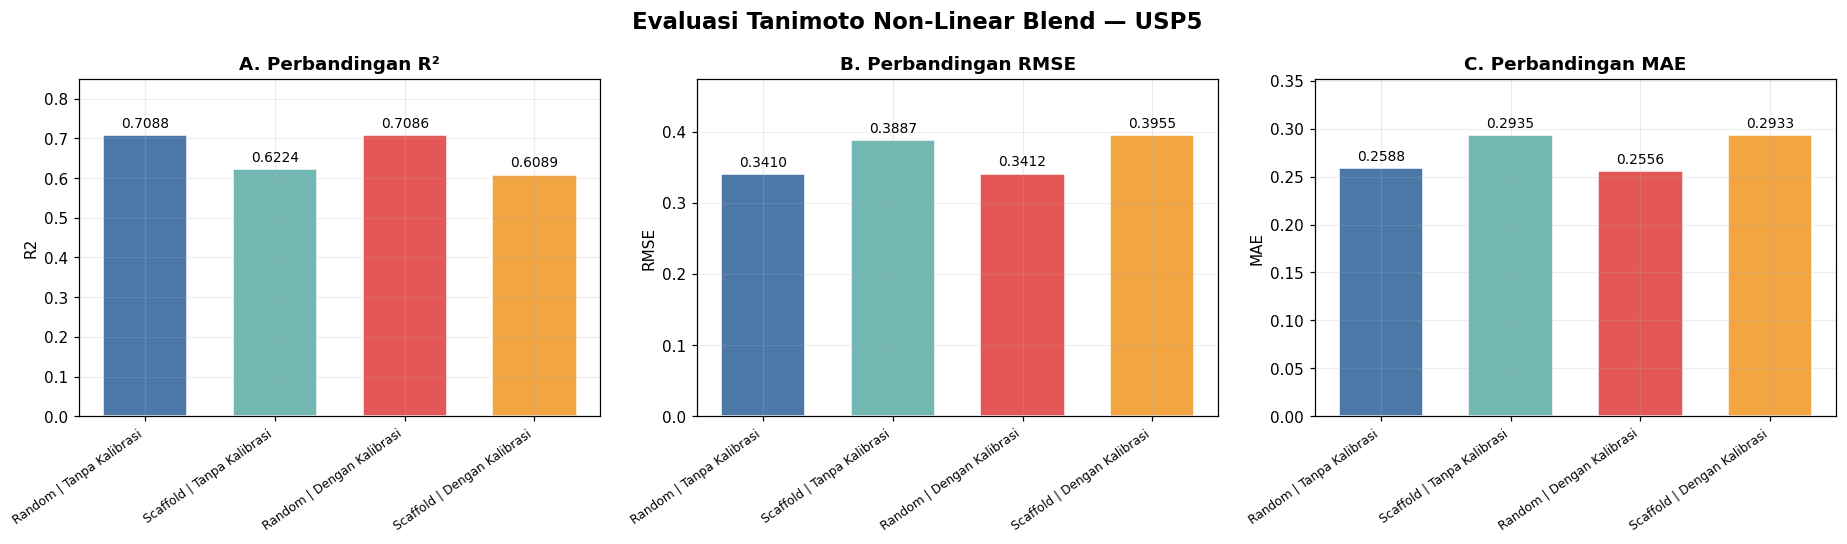

Grafik evaluasi berhasil disimpan.


In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Menggunakan hasil evaluasi Tahap 8
data_plot = final_tbl.copy()

data_plot["Konfigurasi"] = (
    data_plot["Protokol"].str.replace(
        " 5-Fold CV", "", regex=False
    )
    + " | "
    + data_plot["Kalibrasi"].map({
        False: "Tanpa Kalibrasi",
        True: "Dengan Kalibrasi"
    })
)

warna = ["#4C78A8", "#72B7B2", "#E45756", "#F2A541"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrik = ["R2", "RMSE", "MAE"]
judul = [
    "A. Perbandingan R²",
    "B. Perbandingan RMSE",
    "C. Perbandingan MAE"
]

for ax, kolom, title in zip(axes, metrik, judul):

    bars = ax.bar(
        range(len(data_plot)),
        data_plot[kolom],
        color=warna,
        edgecolor="white",
        width=0.65
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

    ax.set_xticks(range(len(data_plot)))
    ax.set_xticklabels(
        data_plot["Konfigurasi"],
        rotation=35,
        ha="right",
        fontsize=8
    )

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(kolom)
    ax.set_ylim(
        0,
        data_plot[kolom].max() * 1.2
    )
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Evaluasi Tanimoto Non-Linear Blend — USP5",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_Blend_Evaluasi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik evaluasi berhasil disimpan.")



### 8.3 Visualisasi Perbandingan Performa Tanimoto Blend

Visualisasi menunjukkan perbandingan performa Tanimoto Blend pada Random dan Scaffold Cross-Validation, baik tanpa maupun dengan kalibrasi linear.

Model tanpa kalibrasi menghasilkan R² tertinggi dan RMSE terendah pada kedua protokol.

Pada Scaffold CV, model tanpa kalibrasi memperoleh R² sebesar 0,6224 dan RMSE 0,3887, sedangkan model dengan kalibrasi memperoleh R² sebesar 0,6089 dan RMSE 0,3955.

Kalibrasi hanya memberikan penurunan MAE yang sangat kecil sehingga belum menunjukkan peningkatan performa secara keseluruhan.

Berdasarkan hasil tersebut, **Tanimoto Blend tanpa kalibrasi dipertahankan sebagai kandidat utama untuk analisis berikutnya**.



## 9. Y-Randomization — Validasi Hubungan Struktur–Aktivitas

### 9.1 Tujuan

Y-Randomization dilakukan untuk memeriksa apakah kemampuan prediksi Tanimoto Blend berasal dari hubungan antara struktur molekul dan pKd, bukan pola acak pada dataset.

### 9.2 Metode

Nilai pKd dari 80 senyawa diacak sebanyak 20 kali, sementara fingerprint molekul tetap dipertahankan.

Pada setiap pengacakan, Tanimoto Blend tanpa kalibrasi dilatih dan dievaluasi ulang menggunakan Random 5-Fold CV dengan seed 100, mengikuti notebook referensi.

Performa model pada label acak dibandingkan dengan performa model menggunakan label asli pada pembagian fold yang sama.

Apabila nilai R² pada label acak jauh lebih rendah dibandingkan data asli, hasil tersebut mendukung bahwa model memanfaatkan hubungan prediktif antara struktur molekul dan aktivitas.

Namun, Y-Randomization tidak menggantikan validasi eksternal dan tidak membuktikan hubungan sebab-akibat biologis.


In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Pemeriksaan komponen
assert X_BLEND.shape[0] == len(y) == 80
assert "TanimotoBlend" in globals()
assert "blend_oof" in globals()

# Pembagian fold yang sama untuk data asli dan acak
folds_y_rand = folds_random(100)

# R2 pada pKd asli, seed 100
pred_asli_9 = blend_oof(
    folds_y_rand,
    calibrate=False,
    y_target=y
)

r2_asli_9 = r2_score(y, pred_asli_9)

# Y-Randomization sebanyak 20 kali
rng9 = np.random.RandomState(0)

hasil_y_random = []

print("=== Y-RANDOMIZATION USP5 ===", flush=True)
print("R2 data asli:", round(r2_asli_9, 4), flush=True)

for i in range(20):

    y_acak = rng9.permutation(y)

    pred_acak = blend_oof(
        folds_y_rand,
        calibrate=False,
        y_target=y_acak
    )

    r2_acak = r2_score(y_acak, pred_acak)

    hasil_y_random.append({
        "Pengacakan": i + 1,
        "R2_Acak": r2_acak
    })

    # Simpan hasil setiap pengacakan
    pd.DataFrame(hasil_y_random).to_csv(
        OUT / "USP5_Y_Randomization_Checkpoint.csv",
        index=False
    )

    print(
        f"Pengacakan {i+1:02d}/20 | "
        f"R2 = {r2_acak:.4f}",
        flush=True
    )

hasil_y_random = pd.DataFrame(hasil_y_random)

print("\n=== RINGKASAN Y-RANDOMIZATION ===")
print("R2 data asli :", round(r2_asli_9, 4))
print(
    "R2 acak mean:",
    round(hasil_y_random["R2_Acak"].mean(), 4)
)
print(
    "R2 acak max :",
    round(hasil_y_random["R2_Acak"].max(), 4)
)
print(
    "R2 acak min :",
    round(hasil_y_random["R2_Acak"].min(), 4)
)

hasil_y_random.to_csv(
    OUT / "USP5_Y_Randomization_20x.csv",
    index=False
)

print("\n=== Y-RANDOMIZATION SELESAI ===")


=== Y-RANDOMIZATION USP5 ===
R2 data asli: 0.6715
Pengacakan 01/20 | R2 = -0.0454
Pengacakan 02/20 | R2 = -0.5001
Pengacakan 03/20 | R2 = -0.3657
Pengacakan 04/20 | R2 = -0.1869
Pengacakan 05/20 | R2 = -0.4980
Pengacakan 06/20 | R2 = -0.2405
Pengacakan 07/20 | R2 = -0.3095
Pengacakan 08/20 | R2 = -0.3925
Pengacakan 09/20 | R2 = -0.0965
Pengacakan 10/20 | R2 = -0.1704
Pengacakan 11/20 | R2 = -0.3001
Pengacakan 12/20 | R2 = -0.3260
Pengacakan 13/20 | R2 = -0.3100
Pengacakan 14/20 | R2 = -0.3895
Pengacakan 15/20 | R2 = -0.2054
Pengacakan 16/20 | R2 = -0.4609
Pengacakan 17/20 | R2 = -0.1688
Pengacakan 18/20 | R2 = -0.3697
Pengacakan 19/20 | R2 = -0.1021
Pengacakan 20/20 | R2 = -0.3571

=== RINGKASAN Y-RANDOMIZATION ===
R2 data asli : 0.6715
R2 acak mean: -0.2898
R2 acak max : -0.0454
R2 acak min : -0.5001

=== Y-RANDOMIZATION SELESAI ===


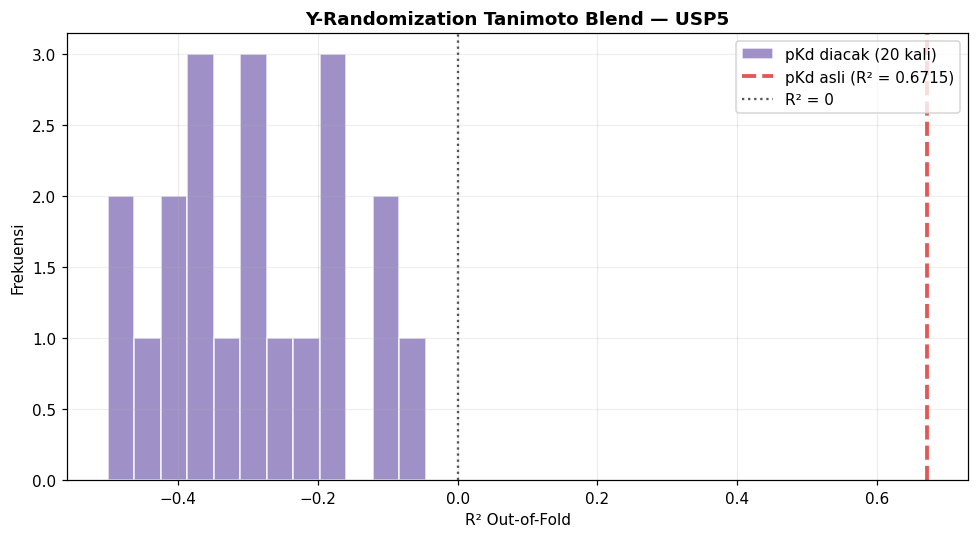

Jumlah R2 acak >= R2 asli: 0 dari 20 pengacakan


In [23]:

import matplotlib.pyplot as plt

r2_acak9 = hasil_y_random["R2_Acak"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    r2_acak9,
    bins=12,
    color="#8E7DBE",
    edgecolor="white",
    alpha=0.85,
    label="pKd diacak (20 kali)"
)

ax.axvline(
    r2_asli_9,
    color="#E45756",
    linewidth=2.5,
    linestyle="--",
    label=f"pKd asli (R² = {r2_asli_9:.4f})"
)

ax.axvline(
    0,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label="R² = 0"
)

ax.set_title(
    "Y-Randomization Tanimoto Blend — USP5",
    fontweight="bold"
)
ax.set_xlabel("R² Out-of-Fold")
ax.set_ylabel("Frekuensi")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_Y_Randomization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Jumlah R2 acak >= R2 asli:",
    int((r2_acak9 >= r2_asli_9).sum()),
    "dari 20 pengacakan"
)



### 9.3 Hasil dan Interpretasi Y-Randomization

Y-Randomization dilakukan sebanyak 20 kali untuk mengevaluasi apakah kemampuan prediksi Tanimoto Non-Linear Blend berkaitan dengan hubungan struktur molekul dan nilai pKd.

Pada Random 5-Fold CV dengan seed 100, model menggunakan pKd asli menghasilkan **R² sebesar 0,6715**.

Setelah nilai pKd diacak sebanyak 20 kali, seluruh nilai R² menjadi negatif dan tidak ada pengacakan yang menghasilkan performa setara atau lebih tinggi dibandingkan data asli (**0 dari 20 pengacakan**).

Hasil ini menunjukkan bahwa model mengalami penurunan performa ketika hubungan antara struktur molekul dan nilai pKd dihilangkan.

**Kesimpulan:** Y-Randomization mendukung bahwa kemampuan prediksi Tanimoto Blend pada data asli berkaitan dengan informasi struktur–aktivitas, bukan semata-mata pola acak pada dataset.

Namun, hasil ini tidak membuktikan hubungan sebab-akibat biologis dan tidak menggantikan validasi eksternal independen. Jumlah 20 pengacakan juga membatasi ketelitian pengujian terhadap kemungkinan hasil acak.



## 10. Diagnostik Prediksi dan Applicability Domain

### 10.1 Tujuan

Tahap ini menganalisis kesalahan prediksi Tanimoto Non-Linear Blend serta hubungan antara kemiripan struktur molekul dan keakuratan prediksi pKd.

Analisis dilakukan menggunakan prediksi out-of-fold (OOF) dari:

- Random 5-Fold CV, seed 700.
- Scaffold 5-Fold CV, seed 800.

Kedua pembagian tersebut mengikuti seed verifikasi yang digunakan pada Tahap 8.

### 10.2 Analisis Residual

Residual dihitung sebagai:

**Residual = pKd eksperimen − pKd prediksi**

- Residual positif: model memprediksi pKd terlalu rendah (underprediction).
- Residual negatif: model memprediksi pKd terlalu tinggi (overprediction).
- Residual mendekati nol: prediksi mendekati nilai eksperimen.

Analisis difokuskan pada penyebaran residual dan kesalahan prediksi senyawa dengan pKd > 5, karena kelompok tersebut hanya terdiri atas 9 senyawa.

### 10.3 Applicability Domain

Applicability Domain dianalisis berdasarkan Tanimoto Similarity antara senyawa testing dan senyawa training.

Nilai similarity yang lebih tinggi menunjukkan fingerprint molekul yang lebih mirip, tetapi tidak secara otomatis menjamin prediksi yang lebih akurat.

Hubungan similarity dengan kesalahan absolut dianalisis menggunakan korelasi Spearman dan pengelompokan berdasarkan tingkat kemiripan.

Kemiripan dihitung terhadap data training masing-masing fold agar tidak memasukkan senyawa testing ke dalam referensi kemiripan.


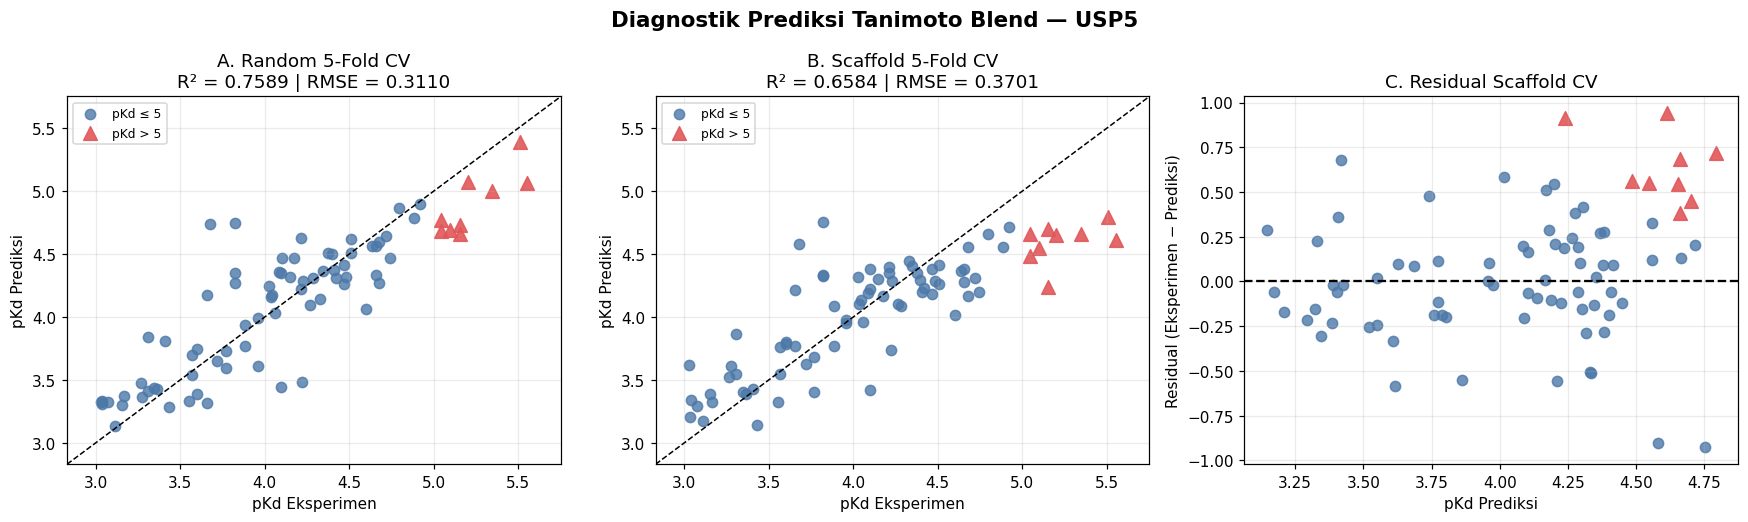

=== DIAGNOSTIK RESIDUAL ===
Random CV R²: 0.7589
Scaffold CV R²: 0.6584

Senyawa pKd > 5: 9
MAE pKd > 5: 0.6389
MAE pKd ≤ 5: 0.2422
Underprediction pKd > 5: 9 dari 9 senyawa
Slope regresi eksperimen terhadap prediksi: 1.174

=== DIAGNOSTIK BERHASIL ===


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Prediksi OOF tanpa kalibrasi
oof_scaf, mem_scaf = blend_oof(
    folds_scaffold(800),
    calibrate=False,
    return_members=True
)

oof_rand = blend_oof(
    folds_random(700),
    calibrate=False
)

# Residual = eksperimen - prediksi
resid = y - oof_scaf
abs_err = np.abs(resid)
high = y > 5

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

lim = [y.min() - 0.2, y.max() + 0.2]

# A dan B: Actual vs Predicted
for a, pred, judul in [
    (ax[0], oof_rand, "A. Random 5-Fold CV"),
    (ax[1], oof_scaf, "B. Scaffold 5-Fold CV")
]:
    a.scatter(
        y[~high], pred[~high],
        s=45, alpha=0.8,
        color="#4C78A8",
        label="pKd ≤ 5"
    )

    a.scatter(
        y[high], pred[high],
        s=80, alpha=0.9,
        color="#E15759",
        marker="^",
        label="pKd > 5"
    )

    a.plot(lim, lim, "k--", linewidth=1)

    r2 = r2_score(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))

    a.set_xlim(lim)
    a.set_ylim(lim)
    a.set_xlabel("pKd Eksperimen")
    a.set_ylabel("pKd Prediksi")
    a.set_title(
        f"{judul}\nR² = {r2:.4f} | RMSE = {rmse:.4f}"
    )
    a.legend(fontsize=8)

# C: Residual Scaffold CV
ax[2].scatter(
    oof_scaf[~high], resid[~high],
    s=45, alpha=0.8,
    color="#4C78A8"
)

ax[2].scatter(
    oof_scaf[high], resid[high],
    s=80, alpha=0.9,
    color="#E15759",
    marker="^"
)

ax[2].axhline(0, color="black", linestyle="--")
ax[2].set_xlabel("pKd Prediksi")
ax[2].set_ylabel("Residual (Eksperimen − Prediksi)")
ax[2].set_title("C. Residual Scaffold CV")

plt.suptitle(
    "Diagnostik Prediksi Tanimoto Blend — USP5",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_Diagnostik_Residual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Ringkasan numerik
print("=== DIAGNOSTIK RESIDUAL ===")
print("Random CV R²:", round(r2_score(y, oof_rand), 4))
print("Scaffold CV R²:", round(r2_score(y, oof_scaf), 4))

print("\nSenyawa pKd > 5:", int(high.sum()))
print(
    "MAE pKd > 5:",
    round(mean_absolute_error(y[high], oof_scaf[high]), 4)
)
print(
    "MAE pKd ≤ 5:",
    round(mean_absolute_error(y[~high], oof_scaf[~high]), 4)
)
print(
    "Underprediction pKd > 5:",
    int((oof_scaf[high] < y[high]).sum()),
    "dari", int(high.sum()), "senyawa"
)
print(
    "Slope regresi eksperimen terhadap prediksi:",
    round(np.polyfit(oof_scaf, y, 1)[0], 4)
)

print("\n=== DIAGNOSTIK BERHASIL ===")


=== APPLICABILITY DOMAIN USP5 ===


,Kelompok,Jumlah,Tanimoto_Rata,MAE
0,Kemiripan rendah,27,0.5832,0.2561
1,Kemiripan sedang,26,0.8353,0.3208
2,Kemiripan tinggi,27,0.9059,0.2848



Spearman rho: -0.0323
p-value: 0.7763
Median Tanimoto: 0.8426
Jumlah Tanimoto < 0.5: 4


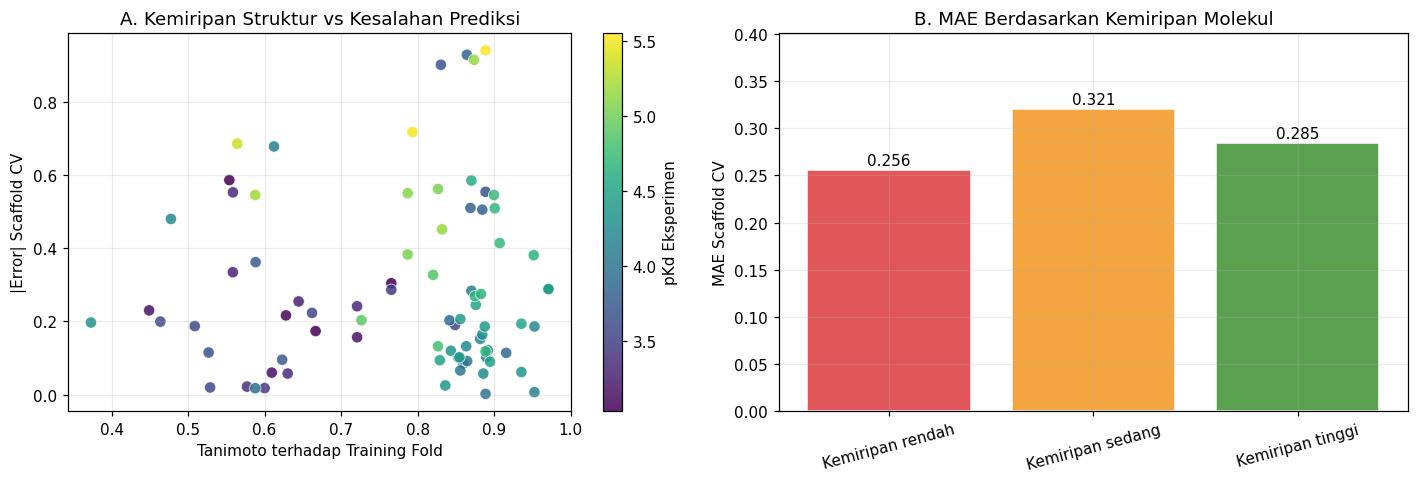


=== 8 SENYAWA DENGAN ERROR TERBESAR ===


,chembl_id,smiles,scaffold,pKd_eksperimen,pKd_prediksi_scaffoldCV,residual,absolute_error,tanimoto_training,pred_SVR-Tanimoto,pred_RF (FP+MACCS),pred_RF (MACCS)
79,CHEMBL5278336,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.5528,4.6124,0.9405,0.9405,0.8889,4.6350,4.7915,4.4106
26,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,O=S(=O)(c1cc[nH]c1)N1CCC(c2ccccc2)CC1,3.8239,4.7522,-0.9283,0.9283,0.8644,4.6305,4.6546,4.9717
74,CHEMBL5270943,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.1549,4.2402,0.9147,0.9147,0.8739,4.2652,4.2944,4.1609
22,CHEMBL5286558,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1,3.6778,4.5788,-0.9011,0.9011,0.8305,4.7054,4.4971,4.5340
78,CHEMBL5266862,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.5086,4.7915,0.7171,0.7171,0.7934,4.6910,4.8852,4.7983
77,CHEMBL5410606,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,O=C(Cn1cnc2ccccc2c1=O)NCc1ccccc1,5.3468,4.6612,0.6856,0.6856,0.5641,4.1231,4.6718,5.1887
39,CHEMBL4440506,CC(C)c1ccc(C(=O)CCC(=O)O)cc1,c1ccccc1,4.0969,3.4190,0.6779,0.6779,0.6122,3.6064,3.3365,3.3140
0,CHEMBL4573416,O=C(O)Cn1cc2ccccc2n1,c1ccc2n[nH]cc2c1,3.0315,3.6176,-0.5861,0.5861,0.5538,3.8371,3.4346,3.5811



=== ANALISIS APPLICABILITY DOMAIN SELESAI ===


In [25]:

from scipy.stats import spearmanr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Kemiripan senyawa testing terhadap training fold
nn_sim_scaf = np.full(len(y), np.nan)

for tr, te in folds_scaffold(800):
    K_test_train = tanimoto_kernel(
        X_FPM[te],
        X_FPM[tr]
    )

    nn_sim_scaf[te] = K_test_train.max(axis=1)

assert np.isfinite(nn_sim_scaf).all()

# Hubungan kemiripan dan error
rho_ad, p_ad = spearmanr(
    nn_sim_scaf,
    abs_err
)

# Kelompok berdasarkan tertil kemiripan
q_ad = pd.qcut(
    nn_sim_scaf,
    3,
    labels=[
        "Kemiripan rendah",
        "Kemiripan sedang",
        "Kemiripan tinggi"
    ]
)

ad_df = pd.DataFrame({
    "Kelompok": q_ad,
    "Tanimoto": nn_sim_scaf,
    "Absolute_Error": abs_err
})

ringkasan_ad = (
    ad_df.groupby("Kelompok", observed=True)
    .agg(
        Jumlah=("Absolute_Error", "size"),
        Tanimoto_Rata=("Tanimoto", "mean"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

print("=== APPLICABILITY DOMAIN USP5 ===")
display(ringkasan_ad.round(4))

print("\nSpearman rho:", round(rho_ad, 4))
print("p-value:", round(p_ad, 4))
print("Median Tanimoto:", round(np.median(nn_sim_scaf), 4))
print(
    "Jumlah Tanimoto < 0.5:",
    int((nn_sim_scaf < 0.5).sum())
)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

scatter = axes[0].scatter(
    nn_sim_scaf,
    abs_err,
    c=y,
    cmap="viridis",
    s=55,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5
)

axes[0].set_title(
    "A. Kemiripan Struktur vs Kesalahan Prediksi"
)
axes[0].set_xlabel("Tanimoto terhadap Training Fold")
axes[0].set_ylabel("|Error| Scaffold CV")

fig.colorbar(
    scatter,
    ax=axes[0],
    label="pKd Eksperimen"
)

# Grafik kelompok kemiripan
axes[1].bar(
    ringkasan_ad["Kelompok"].astype(str),
    ringkasan_ad["MAE"],
    color=["#E15759", "#F2A541", "#59A14F"],
    edgecolor="white"
)

for i, nilai in enumerate(ringkasan_ad["MAE"]):
    axes[1].text(
        i, nilai + 0.005,
        f"{nilai:.3f}",
        ha="center"
    )

axes[1].set_title(
    "B. MAE Berdasarkan Kemiripan Molekul"
)
axes[1].set_ylabel("MAE Scaffold CV")
axes[1].tick_params(axis="x", labelrotation=15)
axes[1].set_ylim(0, ringkasan_ad["MAE"].max() * 1.25)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_Applicability_Domain.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Simpan prediksi per senyawa
pred_df = pd.DataFrame({
    "chembl_id": df["Molecule ChEMBL ID"],
    "smiles": df["Smiles"],
    "scaffold": df["scaffold"],
    "pKd_eksperimen": y,
    "pKd_prediksi_scaffoldCV": oof_scaf,
    "residual": resid,
    "absolute_error": abs_err,
    "tanimoto_training": nn_sim_scaf
})

# Tambahkan prediksi setiap anggota
for nama, pred in mem_scaf.items():
    pred_df["pred_" + nama] = pred

pred_df.to_csv(
    OUT / "USP5_Tanimoto_Prediksi_Per_Senyawa.csv",
    index=False
)

print("\n=== 8 SENYAWA DENGAN ERROR TERBESAR ===")
display(
    pred_df.sort_values(
        "absolute_error",
        ascending=False
    ).head(8).round(4)
)

print("\n=== ANALISIS APPLICABILITY DOMAIN SELESAI ===")



### 10.4 Hasil dan Interpretasi Diagnostik Prediksi

Analisis diagnostik Tanimoto Non-Linear Blend tanpa kalibrasi dilakukan menggunakan prediksi out-of-fold (OOF) pada Random CV seed 700 dan Scaffold CV seed 800.

**Hasil evaluasi:**

| Protokol | R² | RMSE |
|---|---:|---:|
| Random CV | 0,7589 | 0,3110 |
| Scaffold CV | 0,6584 | 0,3701 |

Performa Scaffold CV lebih rendah dibandingkan Random CV, menunjukkan bahwa prediksi pada scaffold yang tidak ditemukan selama training lebih sulit.

**Analisis residual** menunjukkan bahwa seluruh 9 senyawa dengan pKd > 5 mengalami underprediction. Kelompok tersebut memiliki MAE 0,6389, sedangkan senyawa dengan pKd ≤ 5 memiliki MAE 0,2422.

Kesalahan terbesar antara lain ditemukan pada CHEMBL5278336 (0,9405), CHEMBL5276984 (0,9283), dan CHEMBL5270943 (0,9147).

### 10.5 Hasil dan Interpretasi Applicability Domain

Applicability Domain dianalisis menggunakan Tanimoto Similarity terhadap senyawa training pada masing-masing scaffold fold.

Hasil menunjukkan:

- Median Tanimoto: **0,8426**.
- Senyawa dengan Tanimoto < 0,5: **4 senyawa**.
- Korelasi Spearman: **ρ = −0,0323**.
- p-value: **0,7763**.

MAE berdasarkan kelompok kemiripan:

| Kelompok | Jumlah | MAE |
|---|---:|---:|
| Rendah | 27 | 0,2561 |
| Sedang | 26 | 0,3208 |
| Tinggi | 27 | 0,2848 |

Hubungan antara kemiripan molekul dan kesalahan prediksi sangat lemah serta tidak signifikan secara statistik.

Hasil menunjukkan bahwa kemiripan struktur yang tinggi tidak selalu menghasilkan prediksi pKd yang lebih akurat. Beberapa senyawa dengan kemiripan tinggi masih memiliki kesalahan prediksi besar.

**Kesimpulan Tahap 10:** Tanimoto Blend menunjukkan performa prediksi yang cukup baik secara keseluruhan, tetapi masih memiliki keterbatasan pada senyawa dengan pKd tinggi. Tanimoto Similarity dapat menggambarkan kedekatan fingerprint molekul, namun belum cukup digunakan sebagai satu-satunya ukuran keandalan prediksi.



## 11. Efek Kalibrasi pada Senyawa Berpotensi Tinggi

### 11.1 Tujuan

Tahap ini mengevaluasi pengaruh kalibrasi linear terhadap kemampuan Tanimoto Non-Linear Blend dalam memprediksi senyawa inhibitor USP5 dengan pKd > 5.

Analisis Tahap 10 menunjukkan bahwa seluruh 9 senyawa dengan pKd > 5 mengalami underprediction, dengan MAE sebesar 0,6389 pada Scaffold CV seed 800.

### 11.2 Metode

Evaluasi dilakukan menggunakan Repeated Scaffold 5-Fold Cross-Validation dengan seed 800–804.

Dua konfigurasi dibandingkan:

1. Tanimoto Blend tanpa kalibrasi.
2. Tanimoto Blend dengan kalibrasi linear bersarang pada data training.

Metrik yang digunakan adalah R², RMSE, MAE keseluruhan, MAE untuk senyawa pKd > 5, dan MAE untuk senyawa pKd ≤ 5.

Analisis bertujuan menentukan apakah kalibrasi memperbaiki prediksi senyawa berpotensi tinggi, meskipun belum tentu meningkatkan performa keseluruhan.


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Kelompok aktivitas tinggi
high = y > 5

print("=== EVALUASI KALIBRASI USP5 ===")
print("Jumlah senyawa pKd > 5:", int(high.sum()))
print("Jumlah senyawa pKd <= 5:", int((~high).sum()))

assert int(high.sum()) == 9

rows_cal11 = []

for cal in [False, True]:
    for seed in SEEDS_VER_SCAF:

        pred = blend_oof(
            folds_scaffold(seed),
            calibrate=cal
        )

        rows_cal11.append({
            "Kalibrasi": cal,
            "Seed": seed,
            "R2": r2_score(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "MAE_semua": mean_absolute_error(y, pred),
            "MAE_pKd_gt5": mean_absolute_error(
                y[high], pred[high]
            ),
            "MAE_pKd_le5": mean_absolute_error(
                y[~high], pred[~high]
            ),
            "Underprediction_gt5": int(
                (pred[high] < y[high]).sum()
            )
        })

        pd.DataFrame(rows_cal11).to_csv(
            OUT / "Kalibrasi_Tanimoto_Checkpoint.csv",
            index=False
        )

        print(
            f"Kalibrasi={cal} | Seed={seed} | "
            f"R2={r2_score(y, pred):.4f}",
            flush=True
        )

# Ringkasan rata-rata lima seed
cal_detail11 = pd.DataFrame(rows_cal11)

cal_tbl11 = (
    cal_detail11
    .groupby("Kalibrasi")
    .mean(numeric_only=True)
    .drop(columns="Seed")
)

print("\n=== HASIL EFEK KALIBRASI ===")
display(cal_tbl11.round(4))

# Perubahan MAE kelompok pKd tinggi
mae_tanpa = cal_tbl11.loc[False, "MAE_pKd_gt5"]
mae_dengan = cal_tbl11.loc[True, "MAE_pKd_gt5"]

selisih = mae_dengan - mae_tanpa
persen = 100 * (mae_tanpa - mae_dengan) / mae_tanpa

print("\n=== DAMPAK KALIBRASI PADA pKd > 5 ===")
print("MAE tanpa kalibrasi:", round(mae_tanpa, 4))
print("MAE dengan kalibrasi:", round(mae_dengan, 4))
print("Perubahan MAE:", round(selisih, 4))
print("Perbaikan relatif (%):", round(persen, 2))

cal_detail11.to_csv(
    OUT / "USP5_Efek_Kalibrasi_Per_Seed.csv",
    index=False
)

cal_tbl11.to_csv(
    OUT / "USP5_Efek_Kalibrasi_Ringkasan.csv"
)

print("\n=== EVALUASI KALIBRASI SELESAI ===")


=== EVALUASI KALIBRASI USP5 ===
Jumlah senyawa pKd > 5: 9
Jumlah senyawa pKd <= 5: 71
Kalibrasi=False | Seed=800 | R2=0.6584
Kalibrasi=False | Seed=801 | R2=0.5428
Kalibrasi=False | Seed=802 | R2=0.6284
Kalibrasi=False | Seed=803 | R2=0.6316
Kalibrasi=False | Seed=804 | R2=0.6506
Kalibrasi=True | Seed=800 | R2=0.6600
Kalibrasi=True | Seed=801 | R2=0.5348
Kalibrasi=True | Seed=802 | R2=0.5887
Kalibrasi=True | Seed=803 | R2=0.6182
Kalibrasi=True | Seed=804 | R2=0.6429

=== HASIL EFEK KALIBRASI ===


,R2,RMSE,MAE_semua,MAE_pKd_gt5,MAE_pKd_le5,Underprediction_gt5
Kalibrasi,,,,,,
False,0.6224,0.3887,0.2935,0.7009,0.2419,9.0
True,0.6089,0.3955,0.2933,0.6779,0.2446,9.0



=== DAMPAK KALIBRASI PADA pKd > 5 ===
MAE tanpa kalibrasi: 0.7009
MAE dengan kalibrasi: 0.6779
Perubahan MAE: -0.0229
Perbaikan relatif (%): 3.27

=== EVALUASI KALIBRASI SELESAI ===


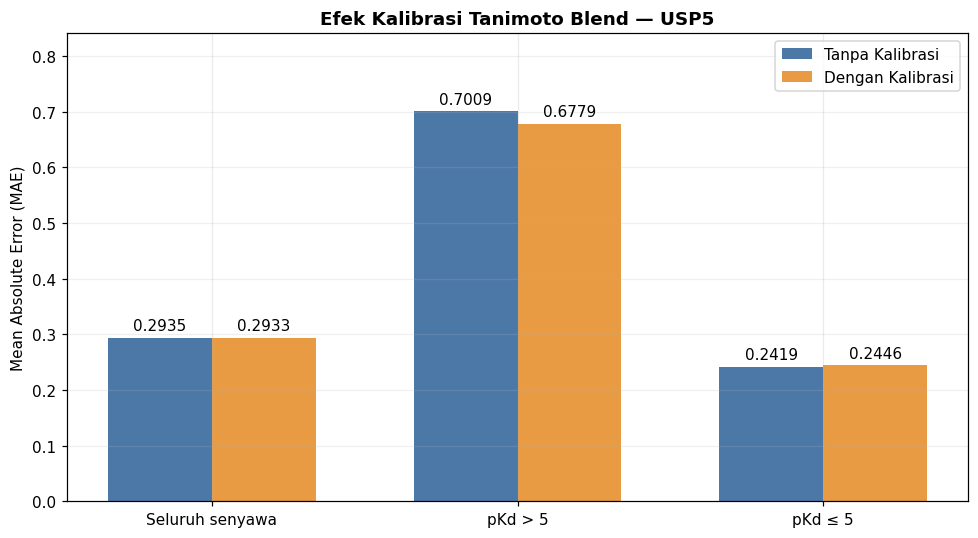

In [27]:

import matplotlib.pyplot as plt
import numpy as np

kategori = [
    "Seluruh senyawa",
    "pKd > 5",
    "pKd ≤ 5"
]

kolom = [
    "MAE_semua",
    "MAE_pKd_gt5",
    "MAE_pKd_le5"
]

tanpa = cal_tbl11.loc[False, kolom].to_numpy()
dengan = cal_tbl11.loc[True, kolom].to_numpy()

x = np.arange(len(kategori))
w = 0.34

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - w/2,
    tanpa,
    w,
    label="Tanpa Kalibrasi",
    color="#4C78A8"
)

bars2 = ax.bar(
    x + w/2,
    dengan,
    w,
    label="Dengan Kalibrasi",
    color="#E89B42"
)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(kategori)
ax.set_ylabel("Mean Absolute Error (MAE)")
ax.set_title(
    "Efek Kalibrasi Tanimoto Blend — USP5",
    fontweight="bold"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)

ax.set_ylim(
    0,
    max(tanpa.max(), dengan.max()) * 1.20
)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Tanimoto_Efek_Kalibrasi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 11.3 Hasil dan Interpretasi Efek Kalibrasi

Evaluasi kalibrasi dilakukan menggunakan Repeated Scaffold 5-Fold Cross-Validation (seed 800–804) untuk membandingkan performa Tanimoto Blend tanpa dan dengan kalibrasi linear.

**Hasil evaluasi:**

| Metrik | Tanpa Kalibrasi | Dengan Kalibrasi |
|---|---:|---:|
| R² | **0,6224** | 0,6089 |
| RMSE | **0,3887** | 0,3955 |
| MAE seluruh senyawa | 0,2935 | 0,2933 |
| MAE pKd > 5 | 0,7009 | **0,6779** |
| MAE pKd ≤ 5 | **0,2419** | 0,2446 |

Kalibrasi menghasilkan penurunan MAE pada kelompok pKd > 5 sebesar **3,27%**, dari 0,7009 menjadi 0,6779.

Namun, seluruh 9 senyawa dengan pKd > 5 tetap mengalami underprediction pada setiap pengulangan, baik sebelum maupun setelah kalibrasi.

Pada keseluruhan dataset, kalibrasi menurunkan R² dari 0,6224 menjadi 0,6089 dan meningkatkan RMSE dari 0,3887 menjadi 0,3955. Perubahan MAE keseluruhan sangat kecil.

**Kesimpulan:** Kalibrasi linear memberikan sedikit perbaikan pada prediksi senyawa ber-pKd tinggi, tetapi belum berhasil mengatasi underprediction dan tidak meningkatkan performa keseluruhan berdasarkan R² dan RMSE.

Oleh karena itu, **Tanimoto Non-Linear Blend tanpa kalibrasi dipertahankan sebagai kandidat model final**, dengan mempertimbangkan performa generalisasi pada Scaffold Cross-Validation.



## 12. Pelatihan dan Penyimpanan Model Final

### 12.1 Tujuan

Tahap ini bertujuan melatih Tanimoto Non-Linear Blend menggunakan seluruh 80 senyawa inhibitor USP5 dan menyimpan model untuk prediksi senyawa baru.

### 12.2 Pemilihan Model Final

Model final terdiri atas tiga anggota:

1. SVR-Tanimoto menggunakan Morgan Fingerprint + MACCS Keys.
2. Random Forest menggunakan Morgan Fingerprint + MACCS Keys.
3. Random Forest menggunakan MACCS Keys.

Prediksi ketiga anggota digabungkan menggunakan rata-rata sederhana dengan bobot masing-masing 1/3.

Berdasarkan evaluasi Repeated Scaffold Cross-Validation pada Tahap 8 dan 11, model **tanpa kalibrasi** dipilih karena menghasilkan R² = 0,6224 ± 0,0414 dan RMSE = 0,3887 ± 0,0207.

Kalibrasi memberikan sedikit perbaikan MAE pada senyawa pKd > 5, tetapi belum meningkatkan R² maupun RMSE keseluruhan.

### 12.3 Pelatihan Model Final

Model final dilatih pada seluruh 80 senyawa setelah evaluasi cross-validation selesai.

Seluruh data digunakan agar model operasional dapat memanfaatkan informasi struktur–aktivitas yang tersedia.

Performa yang dilaporkan tetap berasal dari hasil cross-validation, bukan dari nilai R² atau RMSE pada data training.

Model dan spesifikasi featurization disimpan agar dapat digunakan kembali tanpa mengubah konfigurasi yang telah dievaluasi.


In [28]:

import numpy as np
import pandas as pd
import joblib
from pathlib import Path
from sklearn.metrics import r2_score, mean_squared_error

OUT = Path("/data/Aliya/model/Hasil_Tanimoto_USP5_80")
OUT.mkdir(parents=True, exist_ok=True)

# Pemeriksaan sebelum training
assert len(y) == 80
assert X_BLEND.shape == (80, 379)
assert N_FPM == 258
assert len(FP_MASK) == 1024
assert len(MACCS_MASK) == 167

print("=== TRAINING MODEL FINAL TANIMOTO USP5 ===")

MODEL_FINAL = TanimotoBlend(
    n_fpm=N_FPM,
    C=5.0,
    epsilon=0.05,
    n_estimators=300,
    calibrate=False,
    random_state=0
)

MODEL_FINAL.fit(X_BLEND, y)

print("Model berhasil dilatih.")
print("Jumlah senyawa:", len(y))
print("Jumlah fitur input:", X_BLEND.shape[1])
print("Kalibrasi:", MODEL_FINAL.calibrate)

# Sanity check pada data training
pred_train = MODEL_FINAL.predict(X_BLEND)

r2_train = r2_score(y, pred_train)
rmse_train = np.sqrt(mean_squared_error(y, pred_train))

print("\n=== SANITY CHECK TRAINING ===")
print("R2 training:", round(r2_train, 4))
print("RMSE training:", round(rmse_train, 4))

print("\nCatatan: hasil training bukan performa validasi.")

# Simpan model serta spesifikasi fingerprint
ARTIFACT = {
    "model": MODEL_FINAL,
    "n_fpm": N_FPM,
    "fp_mask": FP_MASK,
    "maccs_mask": MACCS_MASK,
    "fp_radius": 2,
    "fp_nbits": 1024,
    "feature_order": ["FPM", "MACCS"],
    "ensemble_members": [
        "SVR-Tanimoto (FP+MACCS)",
        "RandomForest (FP+MACCS)",
        "RandomForest (MACCS)"
    ],
    "calibrate": False,
    "training_smiles": df["Smiles"].tolist(),
    "training_pKd": y.tolist(),
    "training_fpm": X_FPM.copy(),
    "evaluation": {
        "R2_random_mean": 0.7088,
        "RMSE_random_mean": 0.3410,
        "R2_scaffold_mean": 0.6224,
        "RMSE_scaffold_mean": 0.3887
    }
}

MODEL_PATH = OUT / "USP5_Tanimoto_Blend_Final_80.joblib"

joblib.dump(ARTIFACT, MODEL_PATH)

print("\n=== MODEL FINAL BERHASIL DISIMPAN ===")
print("Lokasi:", MODEL_PATH)
print("Jumlah anggota blend:", 3)
print("Kalibrasi: Tidak")


=== TRAINING MODEL FINAL TANIMOTO USP5 ===
Model berhasil dilatih.
Jumlah senyawa: 80
Jumlah fitur input: 379
Kalibrasi: False

=== SANITY CHECK TRAINING ===
R2 training: 0.9649
RMSE training: 0.1187

Catatan: hasil training bukan performa validasi.

=== MODEL FINAL BERHASIL DISIMPAN ===
Lokasi: /data/Aliya/model/Hasil_Tanimoto_USP5_80/USP5_Tanimoto_Blend_Final_80.joblib
Jumlah anggota blend: 3
Kalibrasi: Tidak


In [29]:

# Buka kembali file yang baru kita simpan sendiri
artifact_check = joblib.load(MODEL_PATH)

model_check = artifact_check["model"]

# Prediksi lima senyawa pertama
pred_awal = MODEL_FINAL.predict(X_BLEND[:5])
pred_baca = model_check.predict(X_BLEND[:5])

assert np.allclose(pred_awal, pred_baca)

print("=== VERIFIKASI MODEL TANIMOTO ===")
print("File model: BERHASIL DIMUAT")
print("Prediksi setelah dimuat: SESUAI")
print("Jumlah senyawa uji:", len(pred_baca))
print("Prediksi contoh:", np.round(pred_baca, 4))
print("Kalibrasi:", artifact_check["calibrate"])
print("\n=== VERIFIKASI BERHASIL ===")


=== VERIFIKASI MODEL TANIMOTO ===
File model: BERHASIL DIMUAT
Prediksi setelah dimuat: SESUAI
Jumlah senyawa uji: 5
Prediksi contoh: [3.1288 3.1416 3.1109 3.1294 3.1212]
Kalibrasi: False

=== VERIFIKASI BERHASIL ===


In [30]:

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, MACCSkeys

def featurize_new(smiles_list, artifact=ARTIFACT):
    mol_new = [Chem.MolFromSmiles(s) for s in smiles_list]

    if any(m is None for m in mol_new):
        raise ValueError("Terdapat SMILES tidak valid.")

    gen = rdFingerprintGenerator.GetMorganGenerator(
        radius=artifact["fp_radius"],
        fpSize=artifact["fp_nbits"]
    )

    F_new = np.array([
        gen.GetFingerprintAsNumPy(m)
        for m in mol_new
    ], dtype=float)

    F_new = F_new[:, artifact["fp_mask"]]

    M_new = np.array([
        np.array(MACCSkeys.GenMACCSKeys(m))
        for m in mol_new
    ], dtype=float)

    M_new = M_new[:, artifact["maccs_mask"]]

    FPM_new = np.hstack([F_new, M_new])
    X_new = np.hstack([FPM_new, M_new])

    return X_new, FPM_new


def predict_pKd(smiles_list, artifact=ARTIFACT):

    X_new, FPM_new = featurize_new(
        smiles_list, artifact
    )

    model = artifact["model"]

    # Prediksi pKd
    pred = model.predict(X_new)

    # Prediksi anggota blend
    members = model.predict_members(X_new)

    # Kemiripan terhadap seluruh training
    sim = tanimoto_kernel(
        FPM_new,
        artifact["training_fpm"]
    ).max(axis=1)

    hasil = pd.DataFrame({
        "SMILES": smiles_list,
        "pKd_prediksi": pred,
        "Kd_nM_prediksi": 10 ** (9 - pred),
        "Tanimoto_training": sim,
        "Status_kemiripan": np.where(
            sim >= 0.5,
            "Similarity >= 0.5",
            "Similarity < 0.5"
        )
    })

    for nama, nilai in members.items():
        hasil["Pred_" + nama] = nilai

    return hasil


print("=== FUNGSI PREDIKSI TANIMOTO BERHASIL DIBUAT ===")


=== FUNGSI PREDIKSI TANIMOTO BERHASIL DIBUAT ===


In [31]:

# Tiga senyawa pertama dari dataset USP5
smiles_uji = df["Smiles"].head(3).tolist()

hasil_prediksi = predict_pKd(smiles_uji)

print("=== UJI FUNGSI PREDIKSI TANIMOTO ===")
display(hasil_prediksi.round(4))

print("\nNilai pKd eksperimen:")
print(np.round(y[:3], 4))

hasil_prediksi.to_csv(
    OUT / "USP5_Tanimoto_Demo_Prediksi.csv",
    index=False
)

print("\n=== UJI PREDIKSI SELESAI ===")


=== UJI FUNGSI PREDIKSI TANIMOTO ===


,SMILES,pKd_prediksi,Kd_nM_prediksi,Tanimoto_training,Status_kemiripan,Pred_SVR-Tanimoto,Pred_RF (FP+MACCS),Pred_RF (MACCS)
0,O=C(O)Cn1cc2ccccc2n1,3.1288,743387.2950,1.0,Similarity >= 0.5,3.0814,3.1505,3.1544
1,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.1416,721815.2685,1.0,Similarity >= 0.5,3.0863,3.1652,3.1732
2,O=C(O)CCc1ncc(-c2ccccc2)o1,3.1109,774662.9809,1.0,Similarity >= 0.5,3.0912,3.1133,3.1281



Nilai pKd eksperimen:
[3.0315 3.0362 3.041 ]

=== UJI PREDIKSI SELESAI ===



### 12.4 Verifikasi Fungsi Prediksi Model Final

Model final Tanimoto Non-Linear Blend diuji menggunakan tiga senyawa yang terdapat dalam dataset training.

Nilai pKd prediksi yang dihasilkan adalah 3,1288; 3,1416; dan 3,1109, sedangkan nilai pKd eksperimennya masing-masing 3,0315; 3,0362; dan 3,0410.

Ketiga contoh menunjukkan bahwa fungsi prediksi mampu menghasilkan nilai pKd, konversi Kd, prediksi anggota ensemble, dan Tanimoto Similarity.

Nilai Tanimoto sebesar 1,0 diperoleh karena senyawa uji juga terdapat dalam dataset training.

**Kesimpulan:** Fungsi prediksi model final berhasil dijalankan. Pengujian ini merupakan pemeriksaan teknis, bukan evaluasi generalisasi, sehingga performa model tetap mengacu pada hasil cross-validation sebelumnya.



# 13. Kesimpulan dan Keterbatasan Model Tanimoto Non-Linear

## 13.1 Ringkasan Penelitian

Penelitian ini mengembangkan model machine learning non-linear berbasis Tanimoto Kernel untuk memprediksi nilai pKd inhibitor USP5 menggunakan dataset 80 senyawa hasil kurasi.

Dataset terdiri atas 80 SMILES unik dan 38 scaffold Bemis–Murcko, dengan rentang pKd 3,0315–5,5528.

Tahapan penelitian meliputi featurization molekul, perhitungan Tanimoto Kernel, screening 11 kandidat model, konstruksi Non-Linear Blend, cross-validation, Y-Randomization, diagnostik residual, Applicability Domain, evaluasi kalibrasi, serta pelatihan dan penyimpanan model final.

---

## 13.2 Hasil Screening Model

Screening dilakukan terhadap 11 konfigurasi algoritma menggunakan Random dan Scaffold 5-Fold Cross-Validation.

**Hasil utama:**

- RandomForest (FP+MACCS) menghasilkan R² Scaffold CV tertinggi sebesar **0,5911**, dengan RMSE 0,4043.
- SVR-Tanimoto (FP+MACCS) menghasilkan R² Random CV tertinggi sebesar **0,6785**.
- RandomForest (MACCS) memberikan performa Scaffold CV yang kompetitif dengan R² 0,5820.

Berdasarkan hasil tersebut, tiga model dipilih sebagai anggota Tanimoto Non-Linear Blend:

1. SVR-Tanimoto (FP+MACCS).
2. RandomForest (FP+MACCS).
3. RandomForest (MACCS).

Prediksi akhir diperoleh melalui rata-rata sederhana ketiga anggota.

---

## 13.3 Evaluasi Final Tanimoto Blend

Evaluasi dilakukan menggunakan repeated 5-fold cross-validation dengan lima pengulangan.

| Protokol | R² Mean ± SD | RMSE Mean ± SD |
|---|---|---|
| Random CV tanpa kalibrasi | **0,7088 ± 0,0393** | **0,3410 ± 0,0227** |
| Scaffold CV tanpa kalibrasi | **0,6224 ± 0,0414** | **0,3887 ± 0,0207** |
| Random CV dengan kalibrasi | 0,7086 ± 0,0392 | 0,3412 ± 0,0225 |
| Scaffold CV dengan kalibrasi | 0,6089 ± 0,0442 | 0,3955 ± 0,0221 |

Model tanpa kalibrasi menunjukkan R² lebih tinggi dan RMSE lebih rendah pada kedua protokol.

Oleh karena itu, **Tanimoto Blend tanpa kalibrasi dipilih sebagai kandidat model final**.

---

## 13.4 Hasil Y-Randomization

Y-Randomization dilakukan sebanyak 20 kali dengan mengacak nilai pKd sambil mempertahankan struktur molekul.

Model menggunakan pKd asli menghasilkan R² sebesar **0,6715** pada Random CV seed 100.

Seluruh hasil pengacakan menunjukkan R² negatif, dan tidak terdapat pengacakan yang mencapai atau melampaui R² data asli (0 dari 20 pengacakan).

Hasil tersebut mendukung bahwa kemampuan prediksi model berkaitan dengan informasi struktur–aktivitas, bukan hanya pola acak pada dataset.

Namun, Y-Randomization tidak menggantikan validasi eksternal independen.

---

## 13.5 Diagnostik Residual

Evaluasi diagnostik pada seed verifikasi 700 dan 800 menghasilkan:

| Protokol | R² | RMSE |
|---|---:|---:|
| Random CV | 0,7589 | 0,3110 |
| Scaffold CV | 0,6584 | 0,3701 |

Analisis residual pada Scaffold CV menunjukkan bahwa seluruh **9 senyawa dengan pKd > 5 mengalami underprediction**.

Kelompok pKd > 5 menghasilkan MAE 0,6389, sedangkan kelompok pKd ≤ 5 menghasilkan MAE 0,2422.

Hasil ini menunjukkan bahwa keterbatasan utama model terdapat pada prediksi senyawa dengan afinitas tinggi.

---

## 13.6 Applicability Domain

Analisis kemiripan molekul dilakukan menggunakan Tanimoto Similarity terhadap training fold pada Scaffold CV.

Hasil menunjukkan:

- Median Tanimoto: **0,8426**.
- Korelasi Spearman antara similarity dan absolute error: **−0,0323**.
- p-value: **0,7763**.
- Jumlah senyawa dengan Tanimoto < 0,5: **4 senyawa**.

Korelasi yang sangat lemah dan tidak signifikan menunjukkan bahwa kemiripan fingerprint yang tinggi tidak selalu berkaitan dengan kesalahan prediksi yang lebih rendah.

Dengan demikian, Tanimoto Similarity belum dapat digunakan sebagai satu-satunya indikator keandalan prediksi.

---

## 13.7 Evaluasi Kalibrasi

Kalibrasi linear menghasilkan penurunan MAE kelompok pKd > 5 dari 0,7009 menjadi 0,6779 atau perbaikan relatif sebesar **3,27%**.

Namun, seluruh sembilan senyawa ber-pKd tinggi tetap mengalami underprediction.

Selain itu, kalibrasi menurunkan R² Scaffold CV dari 0,6224 menjadi 0,6089 dan meningkatkan RMSE dari 0,3887 menjadi 0,3955.

Oleh karena itu, model tanpa kalibrasi dipertahankan karena menunjukkan performa keseluruhan yang lebih baik berdasarkan R² dan RMSE.

---

## 13.8 Model Final

Model final Tanimoto Non-Linear Blend terdiri atas:

- SVR-Tanimoto (FP+MACCS).
- RandomForest (FP+MACCS).
- RandomForest (MACCS).

Ketiga anggota digabungkan dengan bobot sama dan tanpa kalibrasi.

Model dilatih pada seluruh 80 senyawa dengan representasi Morgan Binary Fingerprint dan MACCS Keys.

Fungsi prediksi diuji menggunakan tiga senyawa dari dataset training dan berhasil menghasilkan prediksi pKd, konversi Kd, nilai Tanimoto Similarity, serta prediksi setiap anggota.

Pengujian pada senyawa training merupakan pemeriksaan teknis dan tidak digunakan sebagai ukuran kemampuan generalisasi.

---

## 13.9 Perbandingan dengan ML Ensemble Sebelumnya

| Protokol | ML Ensemble B | Tanimoto Blend |
|---|---:|---:|
| Repeated Random CV — R² | **0,7578** | 0,7088 |
| Repeated Random CV — RMSE | **0,3115** | 0,3410 |
| Scaffold CV — R² | 0,5881 | **0,6224** |
| Scaffold CV — RMSE | 0,4065 | **0,3887** |

Secara deskriptif, ML Ensemble B menghasilkan performa lebih tinggi pada Repeated Random CV, sedangkan Tanimoto Blend menunjukkan performa lebih baik pada Scaffold CV.

Namun, kedua eksperimen menggunakan pembagian fold dan seed yang berbeda, sehingga selisih hasil belum dapat dianggap sebagai bukti keunggulan yang signifikan.

Perbandingan langsung pada pembagian training dan testing yang sama masih diperlukan untuk menentukan pendekatan yang memiliki kemampuan generalisasi lebih baik.

---

## 13.10 Keterbatasan Penelitian

1. Dataset hanya terdiri atas 80 senyawa sehingga performa sensitif terhadap pembagian data.
2. Hanya sembilan senyawa memiliki pKd > 5, menyebabkan keterbatasan pembelajaran pada rentang afinitas tinggi.
3. Seluruh senyawa ber-pKd tinggi masih mengalami underprediction pada evaluasi Scaffold CV.
4. Perbedaan kondisi assay dapat memengaruhi konsistensi data aktivitas.
5. Seleksi fitur awal menggunakan keseluruhan dataset sebelum cross-validation sehingga berpotensi menimbulkan kebocoran informasi dari data validasi.
6. Hasil evaluasi masih berupa cross-validation internal, belum validasi eksternal independen.
7. Applicability Domain berdasarkan kemiripan fingerprint belum tervalidasi secara prospektif.
8. Model blend belum dibandingkan secara langsung dengan seluruh anggota tunggal menggunakan fold verifikasi yang identik.
9. Keunggulan Tanimoto Blend dibandingkan ML Ensemble sebelumnya belum dapat ditentukan secara definitif karena perbedaan protokol evaluasi.

---

## 13.11 Rekomendasi Penelitian Lanjutan

Pengembangan berikutnya disarankan untuk:

1. Memperluas dataset inhibitor USP5, khususnya senyawa ber-pKd tinggi.
2. Melakukan validasi eksternal menggunakan senyawa yang belum digunakan selama pengembangan model.
3. Mengulang evaluasi ML Ensemble dan Tanimoto Blend pada pembagian fold yang identik.
4. Melakukan seleksi fitur di dalam training fold untuk mengurangi potensi data leakage.
5. Meneliti penyebab underprediction pada kelompok senyawa dengan afinitas tinggi.
6. Mengembangkan metode estimasi ketidakpastian dan Applicability Domain yang tervalidasi.

---

## 13.12 Kesimpulan Akhir

Penelitian berhasil mengembangkan Tanimoto Non-Linear Blend untuk prediksi nilai pKd inhibitor USP5 berdasarkan gabungan Morgan Fingerprint dan MACCS Keys.

Model tanpa kalibrasi menghasilkan performa Repeated Random CV dengan **R² = 0,7088 ± 0,0393** dan RMSE **0,3410 ± 0,0227**.

Pada Repeated Scaffold CV, model menghasilkan **R² = 0,6224 ± 0,0414** dan RMSE **0,3887 ± 0,0207**.

Y-Randomization mendukung adanya informasi prediktif dalam hubungan struktur–aktivitas, sementara analisis residual menunjukkan keterbatasan utama pada senyawa ber-pKd tinggi.

Secara keseluruhan, Tanimoto Non-Linear Blend merupakan pendekatan yang menjanjikan untuk prediksi afinitas inhibitor USP5 pada evaluasi internal.

**Namun, kemampuan generalisasi model masih perlu dikonfirmasi melalui evaluasi bebas kebocoran fitur, perbandingan pada fold identik, dan validasi eksternal independen sebelum digunakan untuk pengambilan keputusan eksperimental.**
